# RAVE-VL v4 · Portion 4 — generalisation: HallusionBench safeguard + Qwen3-VL-4B replication

Two pre-registered checks that turn one result into a journal result. Both reuse **exactly** the Portion 1–3 code
(same pre-stage, prompts, gates, merge rule M2 and tests); nothing is re-tuned.

| Part | Question | Data / model | GPU passes |
|---|---|---|---|
| **A** | Does escalation make hallucination worse? (H11: RAVE error ≤ B0 error + 1 pt) | HallusionBench image split (951 yes/no questions, 346 figures), Qwen3-VL-8B | B0 @256 + native, global + crop, crop only (A3), 4 quadrants (B1), up-scaled global (B2) |
| **B** | Does the result replicate on a second backbone? (H0–H4 re-tested) | MMMU-Pro standard-10, Qwen3-VL-4B, Portion 1 crops | B0 frontier (5 budgets), global + crop, B2, A3, A2 |

**Inputs are restored from Google Drive** (`MyDrive/Koushik 2/rave_work/`), outputs mirrored back after every phase, and
this notebook (with outputs) is saved to `Koushik 2/notebooks/`. A100 time continues from Portions 2–3; a pass that
would cross the 7-hour line (minus 15 min) is skipped, never started. HallusionBench pre-stage results are cached on
Drive, so a re-run on a new runtime resumes instead of starting over.

HallusionBench metrics follow its paper: **aAcc** (all questions), **fAcc** (every question about a figure right),
**qAcc** (the same question right on every figure of its set). Questions without an image (178) are excluded: there is
nothing to crop.

In [1]:
%pip install -q "transformers>=4.57.0" accelerate "datasets>=3.0" open_clip_torch opencv-python-headless nvidia-ml-py psutil pandas pyarrow scikit-learn scipy tqdm packaging matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 24.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 4.6 MB/s eta 0:00:00


In [2]:
import os, sys, json, math, re, time, random, string, hashlib, zlib, warnings, shutil, tarfile
from pathlib import Path
import multiprocessing as mp
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

def usable_cpus():
    """CPUs this process may really use (affinity + cgroup quota). os.cpu_count() inside a container often
    reports every host core, which oversubscribes threads and makes CPU work crawl."""
    n = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else (os.cpu_count() or 1)
    try:                                                            # cgroup v2
        q, p = open("/sys/fs/cgroup/cpu.max").read().split()[:2]
        if q != "max":
            n = min(n, max(1, int(q) // int(p)))
    except Exception:
        try:                                                        # cgroup v1
            q = int(open("/sys/fs/cgroup/cpu/cpu.cfs_quota_us").read())
            p = int(open("/sys/fs/cgroup/cpu/cpu.cfs_period_us").read())
            if q > 0:
                n = min(n, max(1, q // p))
        except Exception:
            pass
    return max(1, n)

N_CPU = int(os.environ.get("RAVE_CPUS", usable_cpus()))
for _v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ.setdefault(_v, str(N_CPU))
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
# fewer "out of memory" errors from fragmentation when batch shapes vary (must be set before torch is imported)
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

# ── Storage: fast local working copy + permanent copy in Google Drive ("Koushik 2") ─────────────
# Colab's /content disk is wiped whenever the runtime is recycled (new GPU, disconnect, restart of the VM), so
# every portion works on local disk for speed and mirrors everything to Drive after every phase. The next
# portion restores from Drive automatically, on any runtime.
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
DRIVE_FOLDER = os.environ.get("RAVE_DRIVE_FOLDER", "Koushik 2")
if os.environ.get("RAVE_DRIVE_ROOT"):                 # any folder can stand in for Drive (tests, other machines)
    DRIVE_ROOT = Path(os.environ["RAVE_DRIVE_ROOT"]) / DRIVE_FOLDER
elif IN_COLAB:
    DRIVE_HELP = """Google Drive did not mount ({err}).
How to fix it (most common cause first):
  1. Run this cell again. In the Google sign-in window pick the SAME account that runs this notebook and tick EVERY
     permission box (in particular "See, edit, create and delete all of your Google Drive files"), then Continue.
  2. Or: folder icon in Colab's left sidebar -> "Mount Drive" (mounts without the pop-up), then run this cell again.
  3. Still failing: Runtime -> Disconnect and delete runtime, allow pop-ups for colab.research.google.com, start again.
Nothing has been computed yet, so nothing is lost."""

    def _mount_drive():
        if os.path.isdir("/content/drive/MyDrive"):
            return
        from google.colab import drive
        err = None
        for kw in ({}, {"force_remount": True}):          # second try = a fresh sign-in window
            try:
                drive.mount("/content/drive", timeout_ms=300_000, **kw)
            except Exception as e:                       # e.g. "credential propagation was unsuccessful"
                err = e
                print(f"  Drive mount attempt failed: {type(e).__name__}: {e}")
            if os.path.isdir("/content/drive/MyDrive"):
                return
        raise RuntimeError(DRIVE_HELP.format(err=f"{type(err).__name__}: {err}" if err else "MyDrive not visible"))

    _mount_drive()
    DRIVE_ROOT = Path("/content/drive/MyDrive") / DRIVE_FOLDER
else:
    DRIVE_ROOT = None
if DRIVE_ROOT is not None:
    DRIVE_ROOT.mkdir(parents=True, exist_ok=True)
DRIVE_WORK = DRIVE_ROOT / "rave_work" if DRIVE_ROOT is not None else None
WORK = Path(os.environ.get("RAVE_WORK", "/content/rave_work" if IN_COLAB else "./rave_work")).resolve()
DIRS = {k: WORK / k for k in ["raw", "global", "crops", "meta", "logs", "preds"]}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)
HEAVY_DIRS = {"raw", "global", "crops"}               # thousands of images -> stored on Drive as one tar per dataset

def _walk_small(root):
    for dirpath, dirnames, filenames in os.walk(root):
        dirnames[:] = [d for d in dirnames if d not in HEAVY_DIRS]
        for f in filenames:
            if f == "images.tar" or f.endswith(".partial"):
                continue
            yield Path(dirpath) / f

import threading
_SYNC_LOCK = threading.Lock()
_SYNCED = {}                                           # local path -> (size, mtime_ns) already on Drive

def _key(st):
    return (st.st_size, st.st_mtime_ns)

def sync_to_drive(quiet=True):
    """Copy every new/changed small file (tables, predictions, logs, figures) from WORK to Drive.
    Files already copied are remembered, so Drive (slow to query) is only touched for real changes; each copy goes
    to '<name>.partial' first and is then renamed, so a runtime that dies mid-copy never leaves a broken file."""
    if DRIVE_WORK is None:
        return 0
    n = 0
    with _SYNC_LOCK:
        for p in _walk_small(WORK):
            try:
                st = p.stat()
                if _SYNCED.get(p) == _key(st):
                    continue
                q = DRIVE_WORK / p.relative_to(WORK)
                try:
                    qs = q.stat()
                    if qs.st_size == st.st_size and qs.st_mtime >= st.st_mtime - 2:
                        _SYNCED[p] = _key(st)
                        continue
                except FileNotFoundError:
                    pass
                q.parent.mkdir(parents=True, exist_ok=True)
                tmp = q.with_name(q.name + ".partial")
                shutil.copyfile(p, tmp)
                try:
                    shutil.copystat(p, tmp)                # keeps mtimes when the Drive mount allows it
                except OSError:
                    pass
                os.replace(tmp, q)
                _SYNCED[p] = _key(st)
                n += 1
            except OSError as e:                           # a Drive hiccup must never kill a GPU run
                print(f"  (Drive sync skipped {p.name}: {e})")
    if not quiet:
        print(f"Drive sync: {n} file(s) -> {DRIVE_WORK}")
    return n

def sync_in_background():
    """Non-blocking sync for use inside GPU loops (skipped if a sync is already running)."""
    if DRIVE_WORK is None or _SYNC_LOCK.locked():
        return
    threading.Thread(target=lambda: sync_to_drive(), daemon=True).start()

def archive_images_to_drive(sub=""):
    """Pack raw/, global/, crops/ of WORK/sub into one tar on Drive (thousands of small files are slow on Drive)."""
    if DRIVE_WORK is None:
        return
    base, dst = WORK / sub, DRIVE_WORK / sub / "images.tar"
    dst.parent.mkdir(parents=True, exist_ok=True)
    part = dst.with_name("images.tar.partial")
    with tarfile.open(part, "w") as tf:
        for d in sorted(HEAVY_DIRS):
            if (base / d).exists():
                tf.add(base / d, arcname=d)
    os.replace(part, dst)
    print(f"images archived -> {dst} ({dst.stat().st_size / 1e9:.2f} GB)")

def restore_from_drive(sub="", images=True):
    """Bring WORK/sub back from Drive on a fresh runtime: small files copied, images extracted from the tar."""
    if DRIVE_WORK is None:
        print("no Drive folder configured: using local files only"); return
    src = DRIVE_WORK / sub
    if not src.exists():
        print(f"nothing on Drive yet at {src}"); return
    n = 0
    for p in _walk_small(src):
        q = WORK / p.relative_to(DRIVE_WORK)
        if p.name == "time_ledger.jsonl" and q.exists():   # merge: Drive history + rows this runtime already wrote
            drive_text = p.read_text()
            seen = set(drive_text.splitlines())
            local_new = [l for l in q.read_text().splitlines() if l and l not in seen]
            q.write_text(drive_text + ("" if drive_text.endswith("\n") or not drive_text else "\n")
                         + "".join(l + "\n" for l in local_new))
            n += 1
            continue
        if not q.exists() or q.stat().st_size != p.stat().st_size:
            q.parent.mkdir(parents=True, exist_ok=True); shutil.copy2(p, q); n += 1
        _SYNCED[q] = _key(q.stat())                    # identical to Drive: the next sync skips it
    tar, gdir = src / "images.tar", WORK / sub / "global"
    extracted = False
    if images and tar.exists() and not (gdir.exists() and any(gdir.iterdir())):
        with tarfile.open(tar) as tf:
            try:
                tf.extractall(WORK / sub, filter="data")
            except TypeError:                          # Python < 3.12
                tf.extractall(WORK / sub)
        extracted = True
    print(f"restored {n} file(s) from {src}" + (" + images" if extracted else ""))

def save_notebook_copy(name):
    """Colab only: write this notebook WITH its outputs into Drive/<folder>/notebooks/."""
    if not IN_COLAB or DRIVE_ROOT is None:
        print("not running in Colab: save the notebook yourself"); return
    try:
        from google.colab import _message
        nb = _message.blocking_request("get_ipynb", timeout_sec=120)["ipynb"]
        out = DRIVE_ROOT / "notebooks" / f"{name}_executed_{time.strftime('%Y%m%d_%H%M')}.ipynb"
        out.parent.mkdir(parents=True, exist_ok=True)
        out.write_text(json.dumps(nb))
        print("notebook with outputs ->", out)
    except Exception as e:
        print(f"could not save the notebook automatically ({e}); use File > Save a copy in Drive")

SEED = 20261017
random.seed(SEED)
SMOKE_N = int(os.environ.get("RAVE_SMOKE_N", "0"))       # 0 = full run (1,730 questions); >0 = quick test

DATASET, CONFIG = "MMMU/MMMU_Pro", "standard (10 options)"
MODEL_ID = os.environ.get("RAVE_MODEL_ID", "Qwen/Qwen3-VL-8B-Instruct")

# Qwen3-VL geometry: 16-px patches + 2x2 spatial merge -> 1 LLM visual token per 32x32 px.
FACTOR = 32
PX_PER_TOKEN = FACTOR * FACTOR
MIN_IMG_TOKENS = 64                      # Qwen3-VL default floor (shortest_edge = 65,536 px)
GLOBAL_BUDGETS = [128, 256, 512, 1024]   # Stage-1 visual tokens per QUESTION -> uniform-resolution frontier
NATIVE_CAP = 4096                        # "native" reference: only downscaled above 4,096 tokens per question
BASES = [str(b) for b in GLOBAL_BUDGETS] + ["native"]
MAIN_BASE = "256"                        # pre-registered Stage-1 budget (P1.3 prints the label-free reason)
PROTOCOL_BASE = "1024"                   # v1 protocol budget, kept as the secondary operating point
CROP_TOKENS_MIN, CROP_TOKENS_MAX = 256, 512   # one escalation crop; small regions are up-sampled (= the zoom)
LETTERS = string.ascii_uppercase         # MMMU-Pro standard(10) has 2-12 options (one question has 12)
PH = re.compile(r"<image (\d+)>")
INSTR = "Answer with the option's letter from the given choices directly."
PROMPT_VERSION = "v2-prefix-compatible"
print(f"WORK={WORK} | Drive={DRIVE_WORK} | usable CPUs={N_CPU} (os.cpu_count()={os.cpu_count()}) | "
      f"model={MODEL_ID} | SMOKE_N={SMOKE_N or 'full run'}")

import torch
NOTEBOOK = "P4"
DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"
ON_GPU = DEVICE.startswith("cuda")
LOADER_WORKERS = min(8, max(1, N_CPU - 2))    # 8 keep an A100 busy; more only costs RAM
RUN_HB = os.environ.get("RAVE_P4_HB", "1") == "1"          # Part A
RUN_4B = os.environ.get("RAVE_P4_4B", "1") == "1"          # Part B
MODEL_8B = MODEL_ID
MODEL_4B = os.environ.get("RAVE_MODEL_4B", "Qwen/Qwen3-VL-4B-Instruct")
HB_SMOKE_N = int(os.environ.get("RAVE_HB_SMOKE_N", "0"))   # 0 = all 951 image questions
MAIN_RATE = 0.3
GATE_NAMES = ["RAVE_risk", "LookWise_conf", "LazyMCoT_GBDT", "A1_entropy"]
SAFETY_MIN = 15
N_BOOT = 5000
HB_SUB = "hallusionbench"
HB_DIRS = {k: WORK / HB_SUB / k for k in ["raw", "global", "crops", "meta", "preds"]}
for d_ in HB_DIRS.values():
    d_.mkdir(parents=True, exist_ok=True)
HB_PASSES = [f"global@{MAIN_BASE}", "global@native", f"joint_top1@{MAIN_BASE}", f"croponly_top1@{MAIN_BASE}",
             f"b1_grid4@{MAIN_BASE}", f"b2_upscaled@{MAIN_BASE}"]
R4_B0 = [f"global@{b}" for b in (MAIN_BASE, PROTOCOL_BASE, "128", "512", "native")]
R4_ESC = [f"{k}@{MAIN_BASE}" for k in ("joint_top1", "b2_upscaled", "croponly_top1", "joint_rand")]
R4_PRED = DIRS["preds"] / "qwen3vl4b"
print(f"Part A (HallusionBench, {MODEL_8B}): {RUN_HB} | Part B (replication, {MODEL_4B}): {RUN_4B}")

Mounted at /content/drive
WORK=/content/rave_work | Drive=/content/drive/MyDrive/Koushik 2/rave_work | usable CPUs=12 (os.cpu_count()=12) | model=Qwen/Qwen3-VL-8B-Instruct | SMOKE_N=full run
Part A (HallusionBench, Qwen/Qwen3-VL-8B-Instruct): True | Part B (replication, Qwen/Qwen3-VL-4B-Instruct): True


In [3]:
# ── CPU + GPU time ledger: EVERY executed cell and every named phase gets one row ─────────────
#  cpu_s        CPU-seconds of this kernel + its worker processes (Pool / DataLoader workers)
#  cores_used   cpu_s / wall_s   (how many cores the step really kept busy)
#  gpu_busy_s   phase rows: sum of CUDA-event-timed forward passes (exact)
#               cell rows : integral of NVML GPU utilisation, sampled every 0.25 s (approximate)
#               0.00 + "none" when no GPU is used (e.g. the whole of Portion 1)
#  gpu_energy_J NVML board-energy counter difference (supported on A100)
import time, json, resource, threading, datetime as dt
import psutil

LEDGER = DIRS["logs"] / "time_ledger.jsonl"
WINDOW_FILE = DIRS["logs"] / "a100_window.json"
WINDOW_H = 7.0

def _nvml():
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            import pynvml                        # provided by nvidia-ml-py
        pynvml.nvmlInit()
        cvd = os.environ.get("CUDA_VISIBLE_DEVICES", "0").split(",")[0].strip()
        h = pynvml.nvmlDeviceGetHandleByIndex(int(cvd) if cvd.isdigit() else 0)
        name = pynvml.nvmlDeviceGetName(h)
        return pynvml, h, (name.decode() if isinstance(name, bytes) else name)
    except Exception:
        return None, None, None
NV, NVH, GPU_NAME = _nvml()

def _energy_mJ():
    if NVH is None:
        return None
    try:
        return NV.nvmlDeviceGetTotalEnergyConsumption(NVH)
    except Exception:
        return None

def _torch_cuda():
    t = sys.modules.get("torch")
    try:
        return t if (t is not None and t.cuda.is_available() and t.cuda.is_initialized()) else None
    except Exception:
        return None

def _reaped_child_cpu():
    r = resource.getrusage(resource.RUSAGE_CHILDREN)
    return r.ru_utime + r.ru_stime

def _alive_children():
    out = {}
    try:
        for c in psutil.Process().children(recursive=True):
            try:
                t = c.cpu_times(); out[c.pid] = t.user + t.system
            except psutil.Error:
                pass
    except psutil.Error:
        pass
    return out

GPU_NOTEBOOKS = {"P2", "P3", "P4"}

def _ledger_window_s():
    s = 0.0
    if LEDGER.exists():
        with open(LEDGER) as f:
            for line in f:
                try:
                    r = json.loads(line)
                except ValueError:
                    continue
                if r.get("kind") == "cell" and r.get("notebook") in GPU_NOTEBOOKS and r.get("counts_to_window", True):
                    s += float(r.get("wall_s") or 0)
    return s

def window_used_h():
    """A100 hours used = executed cell time of all GPU portions (P2-P4), summed across runtimes (the ledger lives
    on Drive). Weight downloads are excluded. Idle time between cells is not counted."""
    if globals().get("NOTEBOOK") not in GPU_NOTEBOOKS:
        return None
    s = _ledger_window_s()
    ct = globals().get("CELL_TIMER")
    if ct is not None and ct.m is not None and getattr(ct, "counts", True):
        s += time.perf_counter() - ct.m.t0
    return round(s / 3600, 3)

def window(tag=""):
    used = window_used_h()
    if used is None:
        print(f"⏱ A100 time {tag}: not counted in this portion"); return
    print(f"⏱ A100 time {tag}: {used:.2f} h used, {WINDOW_H - used:.2f} h left of {WINDOW_H:.0f} h (P2–P4 cells)")
    if used > WINDOW_H:
        print("  ⚠ 7-hour budget exceeded")

class _Sampler(threading.Thread):
    def __init__(self, period=0.25):
        super().__init__(daemon=True)
        self.period, self.cpu, self.gpu, self.mem, self.ram = period, [], [], [], []
        self._halt = threading.Event()
    def run(self):
        while not self._halt.wait(self.period):
            self.cpu.append(psutil.cpu_percent(None))
            self.ram.append(psutil.virtual_memory().used / 1e9)
            if NVH is not None:
                try:
                    self.gpu.append(NV.nvmlDeviceGetUtilizationRates(NVH).gpu)
                    self.mem.append(NV.nvmlDeviceGetMemoryInfo(NVH).used / 1e9)
                except Exception:
                    pass
    def stop(self):
        self._halt.set(); self.join(timeout=2)
        return self

class _Meter:
    """Start/stop meter shared by Phase (named steps) and the automatic per-cell timer."""
    def start(self):
        tc = _torch_cuda()
        if tc is not None:
            tc.cuda.synchronize(); tc.cuda.reset_peak_memory_stats()
        self.started = dt.datetime.now().isoformat(timespec="seconds")
        self.kids0 = _alive_children()
        self.t0, self.c0, self.k0, self.e0 = time.perf_counter(), time.process_time(), _reaped_child_cpu(), _energy_mJ()
        self.s = _Sampler(); self.s.start()
        return self
    def stop(self):
        tc = _torch_cuda()
        if tc is not None:
            tc.cuda.synchronize()
        wall = time.perf_counter() - self.t0
        cpu_self = time.process_time() - self.c0
        kids1 = _alive_children()
        reaped = _reaped_child_cpu() - self.k0 - sum(v for p, v in self.kids0.items() if p not in kids1)
        alive = sum(v - self.kids0.get(p, 0.0) for p, v in kids1.items())
        cpu_child = max(0.0, reaped) + max(0.0, alive)
        s = self.s.stop(); e1 = _energy_mJ()
        mean = lambda xs: round(sum(xs) / len(xs), 1) if xs else None
        return dict(started=self.started, wall_s=round(wall, 3), cpu_s=round(cpu_self + cpu_child, 3),
                    cpu_self_s=round(cpu_self, 3), cpu_child_s=round(cpu_child, 3),
                    cores_used=round((cpu_self + cpu_child) / max(wall, 1e-9), 2), sys_cpu_util_pct=mean(s.cpu),
                    gpu_present=(NVH is not None) or (tc is not None), gpu_name=GPU_NAME,
                    gpu_util_pct=mean(s.gpu),
                    gpu_active_s=round(sum(s.gpu) / 100 * s.period, 3) if s.gpu else 0.0,
                    gpu_energy_J=round((e1 - self.e0) / 1000, 1) if (e1 is not None and self.e0 is not None) else None,
                    gpu_mem_used_gb_max=round(max(s.mem), 2) if s.mem else None,
                    gpu_peak_alloc_gb=round(tc.cuda.max_memory_allocated() / 1e9, 2) if tc is not None else None,
                    ram_used_gb_max=round(max(s.ram), 1) if s.ram else round(psutil.virtual_memory().used / 1e9, 1),
                    window_h_used=window_used_h())

def _write(row):
    with open(LEDGER, "a") as f:
        f.write(json.dumps(row, default=str) + "\n")

def _fmt(r):
    if r["gpu_busy_src"] == "none":
        g = "GPU 0.00 s (no GPU used)"
    else:
        g = f"GPU busy {r['gpu_busy_s']:.2f} s [{r['gpu_busy_src']}]"
        if r.get("gpu_util_pct") is not None:
            g += f", util {r['gpu_util_pct']}%"
        if r.get("gpu_energy_J"):
            g += f", {r['gpu_energy_J'] / 1000:.2f} kJ"
        if r.get("gpu_peak_alloc_gb"):
            g += f", peak {r['gpu_peak_alloc_gb']} GB"
    w = f" | A100 time {r['window_h_used']:.2f}/{WINDOW_H:.0f} h" if r.get("window_h_used") is not None else ""
    ram = f" | RAM peak {r['ram_used_gb_max']:.0f} GB" if r.get("ram_used_gb_max") is not None else ""
    return (f"⏱ {r['name']} | wall {r['wall_s']:.2f} s | CPU {r['cpu_s']:.2f} s ({r['cores_used']} cores, "
            f"sys {r['sys_cpu_util_pct']}%) | {g}{ram}{w}" + ("" if r["ok"] else "  ** FAILED **"))

class _GpuTimer:
    """Exact device time of one forward pass (CUDA events; perf_counter if the model runs on CPU)."""
    def __init__(self, phase=None):
        self.phase, self.s = phase, 0.0
    def __enter__(self):
        tc = _torch_cuda(); self.cuda = tc is not None
        if self.cuda:
            self.e0, self.e1 = tc.cuda.Event(enable_timing=True), tc.cuda.Event(enable_timing=True); self.e0.record()
        else:
            self.t0 = time.perf_counter()
        return self
    def __exit__(self, *exc):
        if self.cuda:
            self.e1.record(); self.e1.synchronize(); self.s = self.e0.elapsed_time(self.e1) / 1000
        else:
            self.s = time.perf_counter() - self.t0
        if self.phase is not None:
            self.phase.gpu_busy_s += self.s; self.phase.n_dev_calls += 1
            self.phase.dev_src = "cuda_events" if self.cuda else "cpu_device_forward"
        return False

class Phase:
    """with Phase("P2.B B0", budget_min=10) as ph: ...  -> one 'phase' row (wall, CPU, GPU, energy).
    Wrap each forward pass in `with ph.gpu():` to add its exact CUDA-event time to gpu_busy_s."""
    def __init__(self, name, budget_min=None):
        self.name, self.budget_min, self.extra = name, budget_min, {}
        self.gpu_busy_s, self.n_dev_calls, self.dev_src, self.row = 0.0, 0, None, None
    def gpu(self):
        return _GpuTimer(self)
    def __enter__(self):
        self.m = _Meter().start(); return self
    def __exit__(self, et, ev, tb):
        r = self.m.stop()
        if self.n_dev_calls:
            busy, src = self.gpu_busy_s, self.dev_src
        elif r["gpu_active_s"] > 0:
            busy, src = r["gpu_active_s"], "nvml_util"
        else:
            busy, src = 0.0, ("none" if not r["gpu_present"] or not r["gpu_util_pct"] else "nvml_util")
        self.row = dict(kind="phase", notebook=NOTEBOOK, name=self.name, ok=et is None, **r,
                        gpu_busy_s=round(busy, 3), gpu_busy_src=src, n_forward=self.n_dev_calls,
                        budget_min=self.budget_min, **self.extra)
        _write(self.row); print(_fmt(self.row))
        if self.budget_min and r["wall_s"] > 60 * self.budget_min:
            print(f"  ⚠ over budget: {r['wall_s'] / 60:.1f} min > {self.budget_min} min")
        try:
            sync_in_background()                       # every finished phase goes to Drive (without blocking)
        except Exception as e:
            print(f"  (Drive sync failed: {e})")
        return False

class _CellTimer:
    def __init__(self):
        self.m, self.n, self.counts, self.last_sync = None, 0, True, time.time()
    def pre(self, info=None):
        raw = (getattr(info, "raw_cell", "") or "").strip()
        self.label = raw.splitlines()[0][:60] if raw else ""
        self.counts = "[no-window]" not in self.label           # e.g. weight downloads are not A100 time
        self.m = _Meter().start()
    def post(self, result=None):
        if self.m is None:
            return
        r = self.m.stop()
        self.m = None
        self.n += 1
        src = "nvml_util" if r["gpu_util_pct"] is not None else "none"
        row = dict(kind="cell", notebook=NOTEBOOK, name=f"cell {self.n}: {self.label}",
                   ok=bool(getattr(result, "success", True)), **r, counts_to_window=self.counts,
                   gpu_busy_s=r["gpu_active_s"] if src != "none" else 0.0, gpu_busy_src=src)
        _write(row); print(_fmt(row))
        if time.time() - self.last_sync > 20:
            try:
                sync_in_background(); self.last_sync = time.time()
            except Exception as e:
                print(f"  (Drive sync failed: {e})")

def _register_cell_timer():
    try:
        ip = get_ipython()                       # noqa: F821  (exists inside Jupyter)
    except NameError:
        return None
    old = getattr(ip, "_rave_cell_timer", None)
    if old is not None:
        for ev, fn in (("pre_run_cell", old.pre), ("post_run_cell", old.post)):
            try:
                ip.events.unregister(ev, fn)
            except ValueError:
                pass
    t = _CellTimer()
    ip.events.register("pre_run_cell", t.pre)
    ip.events.register("post_run_cell", t.post)
    ip._rave_cell_timer = t
    t.label = "(timer setup cell)"
    t.m = _Meter().start()                       # so this very cell is logged too
    return t

def time_report(notebook=None, save=True):
    """Totals (from per-cell rows = everything executed) + per-phase CPU/GPU table."""
    import pandas as pd
    if not LEDGER.exists():
        print("ledger empty"); return None
    df = pd.read_json(LEDGER, lines=True)
    if notebook:
        df = df[df.notebook == notebook]
    ce, ph = df[df.kind == "cell"], df[df.kind == "phase"].copy()
    en = ce["gpu_energy_J"].fillna(0).sum() if "gpu_energy_J" in ce else 0.0
    gpu_ph = ph[ph.gpu_busy_src.isin(["cuda_events", "nvml_util"])].gpu_busy_s.sum() if len(ph) else 0.0
    cpu_dev = ph[ph.gpu_busy_src == "cpu_device_forward"].gpu_busy_s.sum() if len(ph) else 0.0
    print(f"[{notebook or 'all notebooks'}] {len(ce)} cells | wall {ce.wall_s.sum() / 60:.1f} min | "
          f"CPU {ce.cpu_s.sum() / 60:.1f} CPU-min ({ce.cpu_s.sum() / max(ce.wall_s.sum(), 1e-9):.1f} cores avg) | "
          f"GPU busy {gpu_ph / 60:.2f} min (phases) / {ce.gpu_busy_s.sum() / 60:.2f} min (cells, NVML) | "
          f"GPU energy {en / 1000:.1f} kJ" + (f" | model forward on CPU (no GPU) {cpu_dev / 60:.2f} min" if cpu_dev else "") +
          (f" | A100 time used (P2–P4) {window_used_h():.2f} h of {WINDOW_H:.0f}" if window_used_h() is not None else ""))
    cols = ["name", "ok", "wall_s", "cpu_s", "cores_used", "sys_cpu_util_pct", "gpu_busy_s", "gpu_busy_src",
            "gpu_util_pct", "gpu_energy_J", "gpu_peak_alloc_gb", "ram_used_gb_max", "n_forward", "budget_min",
            "window_h_used"]
    ph = ph[[c for c in cols if c in ph]].reset_index(drop=True)
    if save:
        ph.to_csv(DIRS["logs"] / f"time_phases_{notebook or 'all'}.csv", index=False)
    return ph

CELL_TIMER = _register_cell_timer()
print("per-cell CPU/GPU timer:", "ON" if CELL_TIMER else "off (not in Jupyter)",
      "| GPU visible:", GPU_NAME or "none", "| ledger:", LEDGER)

per-cell CPU/GPU timer: ON | GPU visible: NVIDIA A100-SXM4-40GB | ledger: /content/rave_work/logs/time_ledger.jsonl
⏱ cell 1: (timer setup cell) | wall 0.01 s | CPU 0.01 s (1.01 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 4 GB | A100 time 0.00/7 h


In [4]:
# [no-window] restore Portions 1-3 (+ any cached HallusionBench pre-stage) from Drive, fetch model weights
restore_from_drive()
restore_from_drive(HB_SUB)
assert (DIRS["meta"] / "manifest.json").exists(), f"Portion 1 outputs not found in {DRIVE_WORK} — run Portion 1 v4 first"
from huggingface_hub import snapshot_download
for mid in ([MODEL_8B] if RUN_HB else []) + ([MODEL_4B] if RUN_4B else []):
    with Phase(f"P4.download {mid} (network, not A100 time)", budget_min=15):
        snapshot_download(mid, max_workers=16)
window("start of Portion 4 (continues from Portions 2-3)")

restored 225 file(s) from /content/drive/MyDrive/Koushik 2/rave_work + images
nothing on Drive yet at /content/drive/MyDrive/Koushik 2/rave_work/hallusionbench


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

⏱ P4.download Qwen/Qwen3-VL-8B-Instruct (network, not A100 time) | wall 50.32 s | CPU 101.80 s (2.02 cores, sys 23.2%) | GPU 0.00 s (no GPU used) | RAM peak 8 GB | A100 time 0.81/7 h


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

⏱ P4.download Qwen/Qwen3-VL-4B-Instruct (network, not A100 time) | wall 25.96 s | CPU 52.01 s (2.0 cores, sys 24.6%) | GPU 0.00 s (no GPU used) | RAM peak 7 GB | A100 time 0.81/7 h
⏱ A100 time start of Portion 4 (continues from Portions 2-3): 0.81 h used, 6.19 h left of 7 h (P2–P4 cells)
⏱ cell 2: # [no-window] restore Portions 1-3 (+ any cached HallusionBe | wall 178.75 s | CPU 165.59 s (0.93 cores, sys 16.3%) | GPU busy 0.00 s [nvml_util], util 0.0%, 8.53 kJ | RAM peak 8 GB | A100 time 0.81/7 h


In [5]:
# ── Statistics used for every claim (paired, per-question) ────────────────────────────────────
import numpy as np

def boot_ci(x, n=5000, seed=SEED):
    x = np.asarray(x, float); rng = np.random.default_rng(seed)
    m = np.array([x[rng.integers(0, len(x), len(x))].mean() for _ in range(n)])
    return float(x.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))

def paired_boot(a, b, n=5000, seed=SEED):
    """mean(a - b), 95% CI, one-sided bootstrap p-value for H0: mean(a - b) <= 0."""
    d = np.asarray(a, float) - np.asarray(b, float); rng = np.random.default_rng(seed)
    m = np.array([d[rng.integers(0, len(d), len(d))].mean() for _ in range(n)])
    return float(d.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5)), float((m <= 0).mean())

def mcnemar_exact(a_correct, b_correct):
    from scipy.stats import binomtest
    a, b = np.asarray(a_correct, bool), np.asarray(b_correct, bool)
    n10, n01 = int((a & ~b).sum()), int((~a & b).sum())
    p = binomtest(n10, n10 + n01, 0.5).pvalue if n10 + n01 else 1.0
    return n10, n01, float(p)

def holm(pvals, alpha=0.05):
    items = sorted(pvals.items(), key=lambda kv: kv[1]); m = len(items); out, stop = {}, False
    for i, (k, p) in enumerate(items):
        stop = stop or p > alpha / (m - i)
        out[k] = dict(p=p, p_holm=min(1.0, max(p * (m - j) for j, (_, p) in enumerate(items[:i + 1]))), reject=not stop)
    return out

def ece(y, p, bins=15):
    y, p = np.asarray(y, float), np.asarray(p, float)
    idx = np.clip(np.digitize(p, np.linspace(0, 1, bins + 1)) - 1, 0, bins - 1)
    return float(sum(abs(y[idx == b].mean() - p[idx == b].mean()) * (idx == b).mean()
                     for b in range(bins) if (idx == b).any()))

def aurc(err, risk):
    """Area under the risk-coverage curve: accept most-confident first; lower is better."""
    o = np.argsort(risk, kind="stable"); e = np.asarray(err, float)[o]
    return float((np.cumsum(e) / np.arange(1, len(e) + 1)).mean())

def boot_ci_fast(x, n=2000, seed=SEED):
    """Bootstrap CI for a mean using a multinomial weight matrix (fast, memory-light)."""
    x = np.asarray(x, float)
    if len(x) < 2:
        return float(x.mean()) if len(x) else float("nan"), float("nan"), float("nan")
    rng = np.random.default_rng(seed)
    w = rng.multinomial(len(x), np.full(len(x), 1 / len(x)), size=n) / len(x)
    m = w @ x
    return float(x.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))

def tex(s):
    return str(s).replace("\\", "/").replace("_", r"\_").replace("%", r"\%").replace("&", r"\&").replace("#", r"\#")

def to_booktabs(df, path, caption, label, align=None):
    """Write a LaTeX booktabs table (no jinja2 dependency)."""
    cols = list(df.columns)
    align = align or ("l" + "r" * (len(cols) - 1))
    lines = [r"\begin{table}[t]", r"\centering", r"\small", rf"\caption{{{tex(caption)}}}", rf"\label{{{label}}}",
             rf"\begin{{tabular}}{{{align}}}", r"\toprule", " & ".join(tex(c) for c in cols) + r" \\", r"\midrule"]
    for row in df.itertuples(index=False):
        lines.append(" & ".join(tex(x) for x in row) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
    Path(path).write_text("\n".join(lines) + "\n")
    print("LaTeX table ->", path)

⏱ cell 3: # ── Statistics used for every claim (paired, per-question)  | wall 0.01 s | CPU 0.01 s (1.02 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 4 GB | A100 time 0.81/7 h


In [6]:
# ── Publication figure style (IEEE column widths, vector PDF + 300-dpi PNG, colour-blind-safe order) ──
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
FIG_DIR = WORK / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
INK, INK2, GRID_C = "#0b0b0b", "#52514e", "#e4e3df"
COL1, COL2 = 3.5, 7.16                       # single / double column width in inches
plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300, "font.family": "DejaVu Sans", "font.size": 8,
    "axes.titlesize": 8.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7, "axes.edgecolor": INK2, "axes.labelcolor": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID_C, "grid.linewidth": 0.5, "axes.axisbelow": True,
    "lines.linewidth": 1.4, "lines.markersize": 4, "legend.frameon": False, "pdf.fonttype": 42, "ps.fonttype": 42,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.03, "figure.facecolor": "white", "axes.facecolor": "white",
    "text.color": INK})
# colour follows the entity in every figure (validated categorical order; markers carry identity too)
NAMES = {"RAVE_risk": "RAVE (risk gate)", "RAVE_VoI": "RAVE (VoI gate)", "LookWise_conf": "LookWise-style gate",
         "LazyMCoT_GBDT": "LazyMCoT-style router", "A1_entropy": "Entropy gate (A1)", "LR_logit": "Answer-only LR",
         "B4_random": "Random (B4)", "Oracle": "Oracle", "B0": "Uniform resolution (B0)"}
COLORS = {"RAVE_risk": "#2a78d6", "LookWise_conf": "#eb6834", "LazyMCoT_GBDT": "#1baf7a", "A1_entropy": "#eda100",
          "LR_logit": "#e87ba4", "RAVE_VoI": "#6250d6", "B4_random": "#8a8985", "Oracle": INK2, "B0": INK}
MARKERS = {"RAVE_risk": "o", "LookWise_conf": "s", "LazyMCoT_GBDT": "^", "A1_entropy": "D", "LR_logit": "v",
           "RAVE_VoI": "P", "B4_random": "x", "Oracle": None, "B0": "o"}

def panel(ax, letter):
    ax.text(-0.02, 1.04, f"({letter})", transform=ax.transAxes, fontsize=9, fontweight="bold", ha="right", va="bottom")

def token_axis(ax, lo, hi):
    """Log x-axis for visual tokens with plain integer ticks at powers of two."""
    from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator
    ax.set_xscale("log")
    ticks = [t for t in (32, 64, 128, 256, 512, 1024, 2048, 4096, 8192) if lo * 0.8 <= t <= hi * 1.25]
    ax.xaxis.set_major_locator(FixedLocator(ticks or [lo, hi]))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.set_xlim(lo * 0.85, hi * 1.18)

def save_fig(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"{name}.{ext}")
    print("figure ->", FIG_DIR / f"{name}.pdf")
    plt.show()
    plt.close(fig)

⏱ cell 4: # ── Publication figure style (IEEE column widths, vector PD | wall 0.01 s | CPU 0.01 s (1.15 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 4 GB | A100 time 0.81/7 h


In [7]:
# ── Prompt construction — identical in every portion (P2 checks token counts against P1) ──────
# Order: [unreferenced images] Question (images inline at <image k>) Options (images inline)
#        [escalation evidence: zoomed crops]  instruction
# Everything before the evidence is byte-identical to the Stage-1 prompt, so a serving engine with
# prefix caching (vLLM / SGLang) re-uses the Stage-1 KV cache and only pays for crop + instruction.
B1_CAPTION = "Zoomed-in views of the four quadrants (top-left, top-right, bottom-left, bottom-right) of {img}:"

def crop_caption(n_images, k):
    return ("Zoomed-in view of a region of the image:" if n_images == 1
            else f"Zoomed-in view of a region of image {k}:")

def build_messages(row, img_paths, extra=None):
    content, order, used = [], [], set()
    def add_text(t):
        if not t:
            return
        if content and content[-1]["type"] == "text":
            content[-1]["text"] += t
        else:
            content.append({"type": "text", "text": t})
    def add_img(p):
        content.append({"type": "image", "image": p}); order.append(p)
    def add_ref(k):
        if k in img_paths and k not in used:
            add_img(img_paths[k]); used.add(k)
        else:
            add_text(f"<image {k}>")
    def interleave(text):
        pos = 0
        for m in PH.finditer(text):
            add_text(text[pos:m.start()]); add_ref(int(m.group(1))); pos = m.end()
        add_text(text[pos:])
    refs = set(json.loads(row.q_refs)) | set(json.loads(row.opt_refs))
    for k in sorted(img_paths):              # images never referenced inline go first
        if k not in refs:
            add_ref(k)
    interleave("Question: " + row.question + "\n")
    add_text("Options:\n")
    for L, o in zip(LETTERS, json.loads(row.options)):
        interleave(f"{L}. {o}\n")
    for cap, p in (extra or []):             # escalation evidence AFTER the Stage-1 prefix
        add_text(cap); add_img(p)
    if extra:
        add_text("\n")
    add_text(INSTR)
    return [{"role": "user", "content": content}], order

VARIANT_KINDS = ["global", "joint_top1", "joint_top3", "joint_rand", "croponly_top1", "b1_grid4", "b2_upscaled"]

def all_variants():
    v = [f"global@{b}" for b in BASES]
    for b in (MAIN_BASE, PROTOCOL_BASE):
        v += [f"{k}@{b}" for k in VARIANT_KINDS[1:]]
    return v

def _abs(p):                                  # artefacts store paths relative to WORK -> portable between machines
    return p if os.path.isabs(p) else str(WORK / p)

def build_maps(IMG, SEL, B2):
    M = {"global": {b: {} for b in BASES}, "crop": {}, "crop_k": {}, "b2": {}, "tok": {}}
    for r in IMG.to_dict("records"):
        for b in BASES:
            p = _abs(r[f"g{b}_path"])
            M["global"][b].setdefault(r["qid"], {})[int(r["k"])] = p
            M["tok"][p] = int(r[f"g{b}_tokens"])
    for r in SEL.to_dict("records"):
        p = _abs(r["crop_path"])
        M["crop"][(r["qid"], r["role"])] = p
        M["crop_k"][(r["qid"], r["role"])] = int(r["k"])
        M["tok"][p] = int(r["crop_tokens"])
    for r in B2.to_dict("records"):
        p = _abs(r["path"])
        M["b2"][(r["qid"], r["base"])] = p
        M["tok"][p] = int(r["tokens"])
    return M

def inputs_for(row, variant, M):
    """variant = '<kind>@<base>'  ->  (images by placeholder index, extra evidence list)."""
    kind, base = variant.split("@")
    q = row.qid
    imgs = dict(M["global"][base].get(q, {}))
    crop = lambda role: (crop_caption(row.n_images, M["crop_k"][(q, role)]), M["crop"][(q, role)])
    extra = []
    if kind == "global":
        pass
    elif kind == "joint_top1":                     # RAVE escalation pass
        extra = [crop("top1")]
    elif kind == "joint_top3":                     # A5: top-3 crops
        extra = [crop(f"top{i}") for i in (1, 2, 3) if (q, f"top{i}") in M["crop"]]
    elif kind == "joint_rand":                     # A2: random region instead of OpenCLIP's choice
        extra = [crop("rand")]
    elif kind == "croponly_top1":                  # A3: crop replaces the global image (no context)
        imgs[M["crop_k"][(q, "top1")]] = M["crop"][(q, "top1")]
    elif kind == "b1_grid4":                       # B1: global + 4 fixed quadrant crops
        kp = M["crop_k"][(q, "b1q0")]
        name = "the image" if row.n_images == 1 else f"image {kp}"
        extra = ([(B1_CAPTION.format(img=name), M["crop"][(q, "b1q0")])]
                 + [("", M["crop"][(q, f"b1q{i}")]) for i in (1, 2, 3)])
    elif kind == "b2_upscaled":                    # B2: same extra tokens spent on the WHOLE image
        imgs[M["crop_k"][(q, "top1")]] = M["b2"][(q, base)]
    else:
        raise ValueError(variant)
    return imgs, extra

⏱ cell 5: # ── Prompt construction — identical in every portion (P2 ch | wall 0.01 s | CPU 0.01 s (1.0 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 4 GB | A100 time 0.81/7 h


In [8]:
# ── Image pre-stage: identical code for MMMU-Pro (Portion 1) and HallusionBench (Portion 4) ───────
import cv2
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm
Image.MAX_IMAGE_PIXELS = None
MAX_CANDIDATES_PER_IMAGE = 20
TOPK_SAVE = 3
N_FOLDS, N_REPEATS = 5, 3
CLIP_OVERRIDE = os.environ.get("RAVE_CLIP")      # e.g. "ViT-L-14,laion2b_s32b_b82k"; default chosen by device
# image types where CLIP reads poorly (text-heavy): edge/text density is mixed into the ranking
DOC_TYPES = {"Tables", "Plots and Charts", "Diagrams", "Mathematical Notations", "Screenshots", "Chemical Structures",
             "Geometric Shapes", "Trees and Graphs", "Maps", "Sheet Music",
             "chart", "table", "ocr", "map", "math", "figure"}          # HallusionBench sub-categories

def smart_resize(h, w, factor=FACTOR, min_pixels=MIN_IMG_TOKENS * PX_PER_TOKEN, max_pixels=16384 * PX_PER_TOKEN):
    h, w = max(float(h), 1.0), max(float(w), 1.0)
    hb = max(factor, round(h / factor) * factor)
    wb = max(factor, round(w / factor) * factor)
    if hb * wb > max_pixels:
        beta = math.sqrt(h * w / max_pixels)
        hb = max(factor, math.floor(h / beta / factor) * factor)
        wb = max(factor, math.floor(w / beta / factor) * factor)
    elif hb * wb < min_pixels:
        beta = math.sqrt(min_pixels / (h * w))
        hb = math.ceil(h * beta / factor) * factor
        wb = math.ceil(w * beta / factor) * factor
    return int(hb), int(wb)

def fit_tokens(h, w, target):
    """Resize (up OR down) so the image uses ~`target` visual tokens (never more)."""
    s = math.sqrt(target * PX_PER_TOKEN / (h * w))
    return smart_resize(h * s, w * s, min_pixels=PX_PER_TOKEN, max_pixels=target * PX_PER_TOKEN)

def n_tokens(hb, wb):
    return (hb // FACTOR) * (wb // FACTOR)

def load_rgb(path):
    im = Image.open(path)
    im.load()
    im = ImageOps.exif_transpose(im)
    if im.mode in ("RGBA", "LA", "P"):
        im = im.convert("RGBA")
        bg = Image.new("RGB", im.size, (255, 255, 255))
        bg.paste(im, mask=im.split()[-1])
        im = bg
    im = im.convert("RGB")
    W, H = im.size                      # Qwen rejects aspect ratio > 200: pad extreme strips
    if max(W, H) / max(1, min(W, H)) > 100:
        side = max(W, H) // 100 + 1
        nw, nh = (W, max(H, side)) if W > H else (max(W, side), H)
        canvas = Image.new("RGB", (nw, nh), (255, 255, 255))
        canvas.paste(im, (0, 0))
        im = canvas
    return im

def _iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0

def candidate_boxes(arr):
    H, W = arr.shape[:2]
    boxes, kinds = [], []
    for r in range(2):                                   # fixed 2x2 grid (B1), order TL, TR, BL, BR
        for c in range(2):
            boxes.append((c * W // 2, r * H // 2, max((c + 1) * W // 2, c * W // 2 + 1),
                          max((r + 1) * H // 2, r * H // 2 + 1))); kinds.append("grid2")
    for r in range(3):                                   # 3x3 overlapping half-size windows
        for c in range(3):
            x0, y0 = int(c * W / 4), int(r * H / 4)
            boxes.append((x0, y0, min(W, x0 + W // 2), min(H, y0 + H // 2))); kinds.append("grid3")
    g = cv2.cvtColor(arr, cv2.COLOR_RGB2GRAY)
    s = min(1.0, 1024 / max(H, W))
    gs = cv2.resize(g, (max(1, int(W * s)), max(1, int(H * s))), interpolation=cv2.INTER_AREA) if s < 1 else g
    edges = cv2.Canny(gs, 50, 150)
    k = max(3, int(0.02 * max(gs.shape)))
    dil = cv2.dilate(edges, cv2.getStructuringElement(cv2.MORPH_RECT, (k, k)))
    n, _, stats, _ = cv2.connectedComponentsWithStats((dil > 0).astype(np.uint8), connectivity=8)
    A = gs.shape[0] * gs.shape[1]
    for j in range(1, n):
        x, y, w, h, _ = stats[j]
        if 0.02 * A <= w * h <= 0.6 * A:
            px, py = 0.08 * w, 0.08 * h
            bx = (max(0, x - px) / s, max(0, y - py) / s, min(gs.shape[1], x + w + px) / s, min(gs.shape[0], y + h + py) / s)
            boxes.append(tuple(int(v) for v in bx)); kinds.append("content")
    ii = cv2.integral((edges > 0).astype(np.uint8))
    def dens(b):
        x0, y0, x1, y1 = [int(round(v * s)) for v in b]
        x1, y1 = min(max(x1, x0 + 1), ii.shape[1] - 1), min(max(y1, y0 + 1), ii.shape[0] - 1)
        x0, y0 = min(x0, x1 - 1), min(y0, y1 - 1)
        tot = ii[y1, x1] - ii[y0, x1] - ii[y1, x0] + ii[y0, x0]
        return float(tot) / max(1, (x1 - x0) * (y1 - y0))
    d = [dens(b) for b in boxes]
    keep = [i for i, kd in enumerate(kinds) if kd == "grid2"]          # always keep the 4 B1 quadrants
    for i in sorted([i for i, kd in enumerate(kinds) if kd != "grid2"], key=lambda i: -d[i]):
        if len(keep) >= MAX_CANDIDATES_PER_IMAGE:
            break
        if all(_iou(boxes[i], boxes[j]) < 0.7 for j in keep):
            keep.append(i)
    return [boxes[i] for i in keep], [kinds[i] for i in keep], [d[i] for i in keep]

def process_image(task):
    qid, k, raw_path, n_img, gdir = task
    cv2.setNumThreads(1)
    im = load_rgb(raw_path)
    W, H = im.size
    nh, nw = smart_resize(H, W)                                   # Qwen3-VL default processing
    rec = dict(qid=qid, k=k, W=W, H=H, native_tokens=n_tokens(nh, nw))
    made = set()
    for b in BASES:
        per = max(16, (NATIVE_CAP if b == "native" else int(b)) // n_img)
        gh, gw = smart_resize(H, W, min_pixels=min(MIN_IMG_TOKENS, per) * PX_PER_TOKEN, max_pixels=per * PX_PER_TOKEN)
        p = Path(gdir) / f"{qid}__img{k}__{gw}x{gh}.png"
        if (gw, gh) not in made and not p.exists():
            im.resize((gw, gh), Image.LANCZOS).save(p, compress_level=1)
        made.add((gw, gh))
        rec.update({f"g{b}_path": str(p), f"g{b}_tokens": n_tokens(gh, gw), f"g{b}_h": gh, f"g{b}_w": gw})
    boxes, kinds, dens = candidate_boxes(np.asarray(im))
    sg = {b: rec[f"g{b}_h"] * rec[f"g{b}_w"] / (H * W) for b in (MAIN_BASE, PROTOCOL_BASE)}
    cands = []
    for ci, (bx, kd, de) in enumerate(zip(boxes, kinds, dens)):
        bw, bh = bx[2] - bx[0], bx[3] - bx[1]
        if kd != "grid2" and (bw < 16 or bh < 16):
            continue
        ch, cw = smart_resize(bh, bw, min_pixels=CROP_TOKENS_MIN * PX_PER_TOKEN, max_pixels=CROP_TOKENS_MAX * PX_PER_TOKEN)
        c = dict(qid=qid, k=k, cid=f"{qid}__img{k}__c{ci}", kind=kd, x0=bx[0], y0=bx[1], x1=bx[2], y1=bx[3],
                 area_frac=bw * bh / (W * H), edge_density=de, crop_h=ch, crop_w=cw, crop_tokens=n_tokens(ch, cw))
        for b, s_ in sg.items():
            c[f"info_gain_{b}"] = min(ch * cw, bw * bh) / max(bw * bh * s_, 1.0)
        cands.append(c)
    return rec, cands

def build_globals(Q_, IMG_, gdir, processes=True):
    """Global images at every budget + crop candidates for every image (all usable cores)."""
    Path(gdir).mkdir(parents=True, exist_ok=True)
    n_img = Q_.set_index("qid").n_images.to_dict()
    tasks = [(r.qid, r.k, r.raw_path, n_img[r.qid], str(gdir)) for r in IMG_.itertuples()]
    if processes:
        pool = mp.get_context("fork").Pool(processes=N_CPU, maxtasksperchild=200)
        try:
            results = list(tqdm(pool.imap_unordered(process_image, tasks, chunksize=4), total=len(tasks)))
        finally:
            pool.close(); pool.join()          # join -> worker CPU time lands in the ledger
    else:
        with ThreadPoolExecutor(max_workers=max(2, N_CPU)) as ex:
            results = list(tqdm(ex.map(process_image, tasks), total=len(tasks)))
    G = pd.DataFrame([r[0] for r in results])
    C_ = pd.DataFrame([c for r in results for c in r[1]])
    return IMG_.merge(G, on=["qid", "k"]), C_

def budget_table(IMG_):
    qtok = IMG_.groupby("qid")[["native_tokens"] + [f"g{b}_tokens" for b in BASES]].sum()
    stat = pd.DataFrame({
        "avg visual tokens / question": [qtok[f"g{b}_tokens"].mean() for b in BASES],
        "% questions down-scaled vs native": [100 * (qtok[f"g{b}_tokens"] < qtok.native_tokens).mean() for b in BASES],
        "% images down-scaled": [100 * (IMG_[f"g{b}_tokens"] < IMG_.native_tokens).mean() for b in BASES]},
        index=[f"global@{b}" for b in BASES]).round(1)
    return stat, qtok

def load_clip():
    """OpenCLIP on the GPU in fp16 (ViT-L/14); CPU-only fallback ViT-B/16 (4x cheaper, less RAM)."""
    import torch, open_clip
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    arch, pre = (CLIP_OVERRIDE or ("ViT-L-14,laion2b_s32b_b82k" if dev == "cuda" else "ViT-B-16,laion2b_s34b_b88k")).split(",")
    flags = open("/proc/cpuinfo").read() if os.path.exists("/proc/cpuinfo") else ""
    amp = (dict(device_type="cuda", dtype=torch.float16) if dev == "cuda"
           else dict(device_type="cpu", dtype=torch.bfloat16, enabled="amx_bf16" in flags))   # CPU bf16 only with AMX
    workers = (min(8, N_CPU - 1) if dev == "cuda" else min(3, N_CPU - 1)) if N_CPU > 1 else 0
    torch.set_num_threads(max(1, N_CPU - workers) if dev == "cpu" else max(1, min(4, N_CPU)))
    model_, _, preprocess = open_clip.create_model_and_transforms(arch, pretrained=pre)
    return dict(model=model_.eval().to(dev), pre=preprocess, tok=open_clip.get_tokenizer(arch), dev=dev, amp=amp,
                workers=workers, per_batch=24 if dev == "cuda" else 4, arch=arch, pretrained=pre)

def _clean_text(s):
    return re.sub(r"\s+", " ", PH.sub(" ", str(s))).strip()

def rank_candidates(Q_, IMG_, C_, clip, ph, max_side=1600):
    """z(CLIP gain) + 0.5 z(edge density) for text-heavy types - 1 if the crop adds < 1.25x real pixels."""
    import torch
    import torch.nn.functional as F
    from torch.utils.data import Dataset, DataLoader
    cand_by_img = {key: g for key, g in C_.groupby(["qid", "k"])}
    img_keys = list(cand_by_img.keys())
    raw_by_img = IMG_.set_index(["qid", "k"]).raw_path.to_dict()
    pre, dev = clip["pre"], clip["dev"]

    class CropSet(Dataset):
        def __len__(self):
            return len(img_keys)
        def __getitem__(self, i):
            key = img_keys[i]
            im = load_rgb(raw_by_img[key])
            f = max(1, math.ceil(max(im.size) / max_side))
            if f > 1:
                im = im.reduce(f)
            boxes = [(r.x0 // f, r.y0 // f, max(r.x1 // f, r.x0 // f + 1), max(r.y1 // f, r.y0 // f + 1))
                     for r in cand_by_img[key].itertuples()]
            return torch.stack([pre(im)] + [pre(im.crop(bx)) for bx in boxes]), i

    def _collate(items):
        return torch.cat([x for x, _ in items]), [x.shape[0] for x, _ in items], [i for _, i in items]

    def _winit(_):
        torch.set_num_threads(1); cv2.setNumThreads(1)

    qtext = {r.qid: _clean_text(r.question) for r in Q_.itertuples()}
    qopts = {r.qid: _clean_text(r.question) + " Options: " + "; ".join(_clean_text(o) for o in json.loads(r.options))
             for r in Q_.itertuples()}
    qids = list(Q_.qid)
    tfeat, clip_gain, n_crops = {}, {}, 0
    m = clip["model"]
    w = clip["workers"]
    with torch.inference_mode(), torch.autocast(**clip["amp"]):
        for s in range(0, len(qids), 256):
            b = qids[s:s + 256]
            with ph.gpu():
                e1 = F.normalize(m.encode_text(clip["tok"]([qtext[q] for q in b]).to(dev)).float(), dim=-1)
                e2 = F.normalize(m.encode_text(clip["tok"]([qopts[q] for q in b]).to(dev)).float(), dim=-1)
            e = F.normalize(e1 + e2, dim=-1)
            tfeat.update({q: e[j] for j, q in enumerate(b)})
        loader = DataLoader(CropSet(), batch_size=clip["per_batch"], num_workers=w, collate_fn=_collate,
                            worker_init_fn=_winit if w else None, pin_memory=dev == "cuda",
                            prefetch_factor=4 if w else None, multiprocessing_context="fork" if w else None)
        for x, sizes, idxs in tqdm(loader, total=len(loader)):
            x = x.to(dev, non_blocking=True)
            with ph.gpu():
                f = F.normalize(m.encode_image(x).float(), dim=-1)
            n_crops += x.shape[0]
            off = 0
            for n, i in zip(sizes, idxs):
                key = img_keys[i]
                sims = (f[off:off + n] @ tfeat[key[0]]).tolist()
                for cid, gn in zip(cand_by_img[key].cid, [v - sims[0] for v in sims[1:]]):
                    clip_gain[cid] = gn
                off += n
    C_ = C_.copy()
    C_["clip_gain"] = C_.cid.map(clip_gain)
    assert C_.clip_gain.notna().all()
    ph.extra.update(device=dev, clip=f"{clip['arch']}/{clip['pretrained']}", crops_encoded=n_crops,
                    crops_per_s=round(n_crops / max(ph.gpu_busy_s, 1e-9)))
    doc_q = {r.qid: bool(set(json.loads(r.img_type)) & DOC_TYPES) for r in Q_.itertuples()}
    def _z(x):
        sd = x.std()
        return (x - x.mean()) / sd if sd and sd > 0 else x * 0
    C_["z_clip"] = C_.groupby("qid").clip_gain.transform(_z).fillna(0)
    C_["z_dens"] = C_.groupby("qid").edge_density.transform(_z).fillna(0)
    C_["score"] = (C_.z_clip + np.where(C_.qid.map(doc_q), 0.5 * C_.z_dens, 0.0)
                   - np.where(C_[f"info_gain_{MAIN_BASE}"] < 1.25, 1.0, 0.0))
    C_["rank"] = C_.groupby("qid").score.rank(ascending=False, method="first").astype(int)
    return C_

def _primary_image(r):
    refs, imgs = json.loads(r.q_refs), json.loads(r.images)
    for k in refs:
        if k in imgs:
            return k
    return imgs[0] if imgs else None

def select_and_materialize(Q_, IMG_, C_, cdir, gdir):
    """top-1/2/3 (RAVE, A5), random (A2), 4 quadrants (B1), token-matched up-scaled global (B2) -> PNG files."""
    Path(cdir).mkdir(parents=True, exist_ok=True)
    prim = {r.qid: _primary_image(r) for r in Q_.itertuples()}
    parts = [C_[C_["rank"] <= TOPK_SAVE].assign(role=lambda d: "top" + d["rank"].astype(str))]
    top1_cid = C_[C_["rank"] == 1].set_index("qid").cid.to_dict()
    rand_rows = []
    for q, g in C_.groupby("qid"):
        pool_ = g[g.cid != top1_cid[q]]
        pool_ = pool_ if len(pool_) else g
        rand_rows.append(pool_.iloc[np.random.default_rng(SEED + zlib.crc32(q.encode())).integers(len(pool_))])
    parts.append(pd.DataFrame(rand_rows).assign(role="rand"))
    b1 = C_[(C_.kind == "grid2") & (C_.k == C_.qid.map(prim))].copy()
    b1["role"] = "b1q" + b1.groupby("qid").cumcount().astype(str)            # TL, TR, BL, BR
    parts.append(b1)
    SEL_ = pd.concat(parts, ignore_index=True)
    SEL_["crop_path"] = [str(Path(cdir) / f"{c}.png") for c in SEL_.cid]
    raw_by_img = IMG_.set_index(["qid", "k"]).raw_path.to_dict()
    imgrow = IMG_.set_index(["qid", "k"])
    b2_rows = []
    for r in SEL_[SEL_.role == "top1"].itertuples():
        ir = imgrow.loc[(r.qid, r.k)]
        for base in (MAIN_BASE, PROTOCOL_BASE):
            target = int(ir[f"g{base}_tokens"]) + int(r.crop_tokens)
            bh, bw = fit_tokens(ir.H, ir.W, target)
            b2_rows.append(dict(qid=r.qid, k=r.k, base=base, target=target, tokens=n_tokens(bh, bw), h=bh, w=bw,
                                path=str(Path(gdir) / f"{r.qid}__img{r.k}__b2_{bw}x{bh}.png")))
    B2_ = pd.DataFrame(b2_rows)

    def save_crop(t):
        raw, box, size, out = t
        if not Path(out).exists():
            load_rgb(raw).crop(box).resize(size, Image.LANCZOS).save(out, compress_level=1)

    def save_b2(t):
        raw, size, out = t
        if not Path(out).exists():
            load_rgb(raw).resize(size, Image.LANCZOS).save(out, compress_level=1)

    jobs = [(raw_by_img[(r.qid, r.k)], (r.x0, r.y0, r.x1, r.y1), (r.crop_w, r.crop_h), r.crop_path)
            for r in SEL_.drop_duplicates("crop_path").itertuples()]
    jobs_b2 = [(raw_by_img[(r.qid, r.k)], (r.w, r.h), r.path) for r in B2_.drop_duplicates("path").itertuples()]
    with ThreadPoolExecutor(max_workers=max(2, N_CPU)) as ex:      # threads: no fork after CUDA init
        list(tqdm(ex.map(save_crop, jobs), total=len(jobs)))
        list(tqdm(ex.map(save_b2, jobs_b2), total=len(jobs_b2)))
    missing = {role: int((~Q_.qid.isin(SEL_[SEL_.role == role].qid)).sum()) for role in ["top1", "rand", "b1q3"]}
    assert all(v == 0 for v in missing.values()), missing
    return SEL_, B2_

def make_folds(Q_, IMG_, strata, extra_groups=None):
    """5 folds x 3 repeats, stratified, grouped so questions sharing an image (or a set) never straddle folds."""
    from sklearn.model_selection import StratifiedGroupKFold
    Q_ = Q_.copy()
    parent = {q: q for q in Q_.qid}
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]; x = parent[x]
        return x
    def union(qs):
        qs = list(qs)
        for q in qs[1:]:
            parent[find(q)] = find(qs[0])
    for _, g in IMG_.groupby("sha1"):
        union(g.qid.unique())
    if extra_groups is not None:
        for _, g in Q_.groupby(extra_groups):
            union(g.qid)
    Q_["group"] = Q_.qid.map(find)
    st = pd.Series(np.asarray(strata), index=Q_.index)
    st = st if st.value_counts().max() >= N_FOLDS else pd.Series(0, index=Q_.index)    # tiny smoke runs
    for rep in range(N_REPEATS):
        sgk = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED + rep)
        col = f"fold_r{rep}"; Q_[col] = -1
        for f, (_, te) in enumerate(sgk.split(Q_, st, groups=Q_.group)):
            Q_.loc[Q_.index[te], col] = f
    Q_["fold"] = Q_.fold_r0
    return Q_

def exact_seq_lengths(Q_, IMG_, SEL_, B2_, variants, proc):
    """Exact visual + sequence tokens of every prompt variant, with the real Qwen3-VL chat template."""
    for b in BASES:
        IMG_[f"g{b}_tokens"] = IMG_[f"g{b}_tokens"].astype(int)
    maps = build_maps(IMG_, SEL_, B2_)
    qrow = {r.qid: r for r in Q_.itertuples()}
    tk, PAD, rows = proc.tokenizer, "<|image_pad|>", []
    for v in variants:
        texts, meta = [], []
        for q in Q_.qid:
            imgs, extra = inputs_for(qrow[q], v, maps)
            msgs, order = build_messages(qrow[q], imgs, extra)
            texts.append(proc.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True))
            meta.append((q, sum(maps["tok"][p] for p in order), len(order)))
        lens = [len(x) for x in tk(texts, add_special_tokens=False)["input_ids"]]
        for (q, vis, n), L, t in zip(meta, lens, texts):
            assert t.count(PAD) == n
            rows.append(dict(qid=q, variant=v, vis_tokens=vis, seq_len=L - n + vis, n_img_inputs=n))
    return pd.DataFrame(rows)

def question_features(Q_, IMG_, SEL_, SEQ_):
    """Evidence-availability features used by the RAVE gate (label-free, inference-time only)."""
    Q_ = Q_.copy()
    top1 = SEL_[SEL_.role == "top1"].set_index("qid")
    Q_["native_tokens_q"] = Q_.qid.map(IMG_.groupby("qid").native_tokens.sum())
    for b in BASES:
        Q_[f"g{b}_tokens_q"] = Q_.qid.map(IMG_.groupby("qid")[f"g{b}_tokens"].sum())
    for b in (MAIN_BASE, PROTOCOL_BASE):
        Q_[f"top1_info_gain_{b}"] = Q_.qid.map(top1[f"info_gain_{b}"])
    Q_["top1_clip_gain"] = Q_.qid.map(top1.clip_gain)
    Q_["top1_score"] = Q_.qid.map(top1.score)
    Q_["top1_edge_density"] = Q_.qid.map(top1.edge_density)
    Q_["top1_tokens"] = Q_.qid.map(top1.crop_tokens)
    Q_["text_tokens"] = Q_.qid.map(SEQ_[SEQ_.variant == f"global@{MAIN_BASE}"].set_index("qid").eval("seq_len - vis_tokens"))
    assert Q_[["native_tokens_q", "top1_clip_gain", "text_tokens"]].notna().all().all()
    return Q_

def _sha256_file(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def save_tables(meta_dir, tables, manifest):
    """Parquet tables with image paths stored RELATIVE to WORK (portable) + manifest with SHA-256 of each."""
    meta_dir = Path(meta_dir); meta_dir.mkdir(parents=True, exist_ok=True)
    rel = lambda s_: s_.map(lambda p: os.path.relpath(p, WORK))
    path_cols = {"images": ["raw_path"] + [f"g{b}_path" for b in BASES], "crops": ["crop_path"], "b2": ["path"]}
    for name, df in tables.items():
        df = df.copy()
        for c in path_cols.get(name, []):
            if c in df:
                df[c] = rel(df[c])
        df.to_parquet(meta_dir / f"{name}.parquet", index=False)
    manifest["sha256"] = {n: _sha256_file(meta_dir / f"{n}.parquet") for n in tables}
    (meta_dir / "manifest.json").write_text(json.dumps(manifest, indent=2, default=str))
    return manifest

⏱ cell 6: # ── Image pre-stage: identical code for MMMU-Pro (Portion 1 | wall 0.50 s | CPU 1.83 s (3.66 cores, sys 31.4%) | GPU busy 0.00 s [nvml_util], util 0.0%, 0.02 kJ | RAM peak 4 GB | A100 time 0.81/7 h


In [9]:
# ── Offline evaluation shared by Portions 3 and 4: merge rules, policies, random expectation ────
W_GRID = [round(0.1 * i, 1) for i in range(11)]
RATE_GRID = [round(0.05 * i, 2) for i in range(21)]

def esc_mask(score, r):
    """Escalate the top-r share by score (stable ties = the order used for pre-registration)."""
    k = int(round(r * len(score))); m = np.zeros(len(score), bool)
    if k:
        m[np.argsort(-np.asarray(score), kind="stable")[:k]] = True
    return m

class Evaluator:
    """One dataset x one model. b0[base] = Stage-1 predictions, esc[(kind, base)] = dense escalation passes."""
    def __init__(self, Q_, b0, esc, costs=None, cost_tag=""):
        self.Q = Q_.reset_index(drop=True); self.N = len(self.Q)
        self.ans = self.Q.answer_idx.values.astype(int)
        self.folds = self.Q.fold_r0.values
        self.width = max(MAX_OPT, int(self.Q.n_opt.max()))
        self.valid = np.arange(self.width)[None, :] < self.Q.n_opt.values[:, None]
        self.costs, self.tag = (costs or {}), cost_tag
        self.RES, self.MERGE = {}, {}
        for base, df in b0.items():
            g = self.aligned(df)
            self.RES[base] = {"global": self._pack(g)}
            self.MERGE[base] = {}
        for (kind, base), df in esc.items():
            if base in self.RES:
                self.RES[base][kind] = self._pack(self.aligned(df))
                self.MERGE[base][kind] = self._merge(base, kind)

    def aligned(self, df):
        return df.set_index("qid").loc[self.Q.qid].reset_index()

    def _pack(self, d):
        return dict(P=self.prob_matrix(d.probs), correct=d.correct.values.astype(int),
                    vis=d.vis_tokens.values.astype(float), gpu=d.gpu_s.values.astype(float))

    def prob_matrix(self, col):
        P = np.zeros((len(col), self.width))
        for i, p in enumerate(col):
            P[i, :len(p)] = p
        return P

    def pooled(self, Pg, Pe, w, valid=None):
        valid = self.valid if valid is None else valid
        z = (1 - w) * np.log(np.clip(Pg, 1e-12, 1)) + w * np.log(np.clip(Pe, 1e-12, 1))
        z = np.where(valid, z, -np.inf)
        z = z - z.max(1, keepdims=True)
        p = np.exp(z)
        return p / p.sum(1, keepdims=True)

    def nll(self, P, idx):
        return float(-np.log(np.clip(P[idx, self.ans[idx]], 1e-12, 1)).mean()) if len(idx) else float("nan")

    def _merge(self, base, kind):
        Pg, Pe = self.RES[base]["global"]["P"], self.RES[base][kind]["P"]
        curves = {w: self.pooled(Pg, Pe, w) for w in W_GRID}
        m2_pred, w_fold = np.zeros(self.N, int), {}
        for fo in np.unique(self.folds):
            tr, te = np.where(self.folds != fo)[0], self.folds == fo
            best = min(W_GRID, key=lambda w: self.nll(curves[w], tr))
            w_fold[int(fo)] = best
            m2_pred[te] = curves[best][te].argmax(1)
        m3_pred = np.where(Pe.max(1) > Pg.max(1), Pe.argmax(1), Pg.argmax(1))
        return dict(M1=(Pe.argmax(1) == self.ans).astype(int), M2=(m2_pred == self.ans).astype(int),
                    M3=(m3_pred == self.ans).astype(int), w=w_fold, m2_pred=m2_pred,
                    nll=[self.nll(curves[w], np.arange(self.N)) for w in W_GRID])

    def has(self, base, kind):
        return kind in self.MERGE.get(base, {})

    def energy(self, variant):
        e = (self.costs.get(self.tag + variant) or {}).get("energy_J_per_q")
        return float(e) if e is not None else float("nan")

    def gain(self, base, kind="joint_top1", merge="M2"):
        return self.MERGE[base][kind][merge] - self.RES[base]["global"]["correct"]

    def policy(self, base, esc, kind="joint_top1", merge="M2"):
        g, e = self.RES[base]["global"], self.RES[base][kind]
        esc = np.asarray(esc, bool)
        final = np.where(esc, self.MERGE[base][kind][merge], g["correct"])
        tok = g["vis"] + esc * e["vis"]
        tok_pc = g["vis"] + esc * (np.maximum(e["vis"] - g["vis"], 0) if kind.startswith("joint") else e["vis"])
        return dict(correct=final, tok=tok, tok_pc=tok_pc, comp=g["gpu"] + esc * e["gpu"], rate=esc.mean(),
                    energy=self.energy(f"global@{base}") + esc.mean() * self.energy(f"{kind}@{base}"))

    def b4_expected(self, base, r, kind="joint_top1", merge="M2"):
        g = self.RES[base]["global"]["correct"]
        return g + r * (self.MERGE[base][kind][merge] - g)

    def oracle_mask(self, base, r, kind="joint_top1"):
        return esc_mask(self.gain(base, kind) * 10 - self.RES[base][kind]["vis"] / 1e6, r)

    def curves(self, base, scores, kind="joint_top1", rates=RATE_GRID):
        """Accuracy / tokens / compute for every gate at every escalation rate (+ random expectation, oracle)."""
        g, e, rows = self.RES[base]["global"], self.RES[base][kind], []
        for name, sc in scores.items():
            for r in rates:
                p_ = self.policy(base, esc_mask(sc, r), kind)
                rows.append(dict(base=base, policy=name, rate=r, acc=p_["correct"].mean(), tok=p_["tok"].mean(),
                                 tok_pc=p_["tok_pc"].mean(), comp=p_["comp"].mean(), energy=p_["energy"]))
        gn = self.gain(base, kind)
        for r in rates:
            rows.append(dict(base=base, policy="B4_random", rate=r, acc=g["correct"].mean() + r * gn.mean(),
                             tok=g["vis"].mean() + r * e["vis"].mean(),
                             tok_pc=g["vis"].mean() + r * np.maximum(e["vis"] - g["vis"], 0).mean(),
                             comp=g["gpu"].mean() + r * e["gpu"].mean(),
                             energy=self.energy(f"global@{base}") + r * self.energy(f"{kind}@{base}")))
            p_ = self.policy(base, self.oracle_mask(base, r, kind), kind)
            rows.append(dict(base=base, policy="Oracle", rate=r, acc=p_["correct"].mean(), tok=p_["tok"].mean(),
                             tok_pc=p_["tok_pc"].mean(), comp=p_["comp"].mean(), energy=p_["energy"]))
        return pd.DataFrame(rows)

def frontier_gap(c_policy, tok_policy, b0_frames, Qorder, n_boot=2000, seed=SEED):
    """Accuracy above the uniform-resolution frontier, interpolated at the policy's average visual tokens."""
    PV = np.stack([df.set_index("qid").loc[Qorder].vis_tokens.values for df in b0_frames]).astype(float)
    PC = np.stack([df.set_index("qid").loc[Qorder].correct.values for df in b0_frames]).astype(float)
    c_policy, tok_policy = np.asarray(c_policy, float), np.asarray(tok_policy, float)
    def gap(w):
        xs, ys = PV @ w, PC @ w
        o = np.argsort(xs)
        return float(c_policy @ w - np.interp(tok_policy @ w, xs[o], ys[o]))
    n = len(Qorder)
    W = np.random.default_rng(seed).multinomial(n, np.full(n, 1 / n), size=n_boot) / n
    gaps = np.array([gap(w) for w in W])
    return gap(np.full(n, 1 / n)), float(np.percentile(gaps, 2.5)), float(np.percentile(gaps, 97.5)), float((gaps <= 0).mean())

⏱ cell 7: # ── Offline evaluation shared by Portions 3 and 4: merge ru | wall 0.01 s | CPU 0.01 s (1.0 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 4 GB | A100 time 0.81/7 h


## Load Portion 1 artefacts (MMMU-Pro) and Portion 2–3 results

In [10]:
def sha256(p):
    return _sha256_file(p)

def make_ctx(Q_, IMG_, SEL_, B2_, SEQ_):
    return dict(Q=Q_, IMG=IMG_, SEL=SEL_, B2=B2_, SEQ=SEQ_, QROW={r.qid: r for r in Q_.itertuples()},
                MAPS=build_maps(IMG_, SEL_, B2_),
                EST={v: dict(zip(g.qid, g.seq_len)) for v, g in SEQ_.groupby("variant")},
                VIS={v: dict(zip(g.qid, g.vis_tokens)) for v, g in SEQ_.groupby("variant")})

def load_meta(meta_dir):
    man = json.loads((Path(meta_dir) / "manifest.json").read_text())
    for name, h in man["sha256"].items():
        assert sha256(Path(meta_dir) / f"{name}.parquet") == h, f"{name}.parquet changed since it was written"
    return man, {n: pd.read_parquet(Path(meta_dir) / f"{n}.parquet") for n in man["sha256"]}

with Phase("P4.0 load + verify MMMU-Pro artefacts", budget_min=2):
    MAN, T = load_meta(DIRS["meta"])
    MM = make_ctx(T["questions"], T["images"], T["crops"], T["b2"], T["seq_lengths"])
assert MAN["prompt_version"] == PROMPT_VERSION and MAN["smoke_n"] == SMOKE_N
Q, QROW, MAPS, EST, VIS = MM["Q"], MM["QROW"], MM["MAPS"], MM["EST"], MM["VIS"]
_tf = DIRS["logs"] / "hypothesis_tests.json"
TESTS_8B = json.loads(_tf.read_text()) if _tf.exists() else {}
_pf = DIRS["logs"] / "gpu_profile.json"
PROFILE = json.loads(_pf.read_text()) if _pf.exists() else {}
print(f"MMMU-Pro: {len(Q)} questions | 8B tests from Portion 3: {'found' if TESTS_8B else 'not found (run P3 first)'}")

⏱ P4.0 load + verify MMMU-Pro artefacts | wall 0.67 s | CPU 0.54 s (0.81 cores, sys 14.3%) | GPU 0.00 s (no GPU used) | RAM peak 4 GB | A100 time 0.81/7 h
MMMU-Pro: 1730 questions | 8B tests from Portion 3: found
⏱ cell 8: def sha256(p): | wall 0.68 s | CPU 0.56 s (0.82 cores, sys 8.1%) | GPU busy 0.00 s [nvml_util], util 0.0%, 0.03 kJ | RAM peak 4 GB | A100 time 0.81/7 h


In [11]:
# ── Model, data path and scoring: identical code in Portions 2 and 3 ────────────────────────────
import importlib, gc, transformers
import pandas as pd
from packaging import version
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from transformers import AutoProcessor, Qwen3VLForConditionalGeneration

torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
torch.set_num_threads(N_CPU)
COST_FILE = DIRS["logs"] / "variant_costs.json"
PROFILE_FILE = DIRS["logs"] / "gpu_profile.json"
PRED_DIR = DIRS["preds"]          # where dense passes are written (Portion 4 points this elsewhere)
COST_TAG = ""                     # prefix of the per-pass cost records (Portion 4: "hb|" or "4b|")
MAX_OPT = 12                      # MMMU-Pro has up to 12 options (letters A-L); HallusionBench has 2
MAX_TOK = 16384                   # batch token budget; replaced by the autotune / the saved GPU profile
PROFILE_VERSION = 2               # v2: throughput-optimal budget + host-RAM cap (profiles of older runs are redone)

# ── Host-RAM governor ───────────────────────────────────────────────────────────────────────────
# Every LLM visual token is 4 patches x 1536 pixel values. The processor builds them in float32 (24.6 kB per
# visual token, ~3x that while resizing / normalising / patchifying); the batch is then cast to bf16 (12.3 kB) —
# bit-identical to the model's own first step (pixel_values.type(visual.dtype)). Batches in flight =
# workers x prefetch (+2 in the main process). Batches are capped in visual tokens so that this stays inside a
# fixed share of the free RAM, whatever the GPU, the batch budget or the image sizes.
PREFETCH = 2
_VIS_BYTES_READY = 4 * 1536 * 2
_VIS_BYTES_BUILD = 4 * 1536 * 4 * 3
RAM_FRACTION, RAM_CAP_GB = 0.40, 24       # loader may use <= 40% of the free RAM, and never more than 24 GB
RAM_PANIC_PCT = 90                        # above this the loader is restarted with half-size batches
MAX_VIS = 32768

def plan_host_ram():
    vm = psutil.virtual_memory()
    budget = min(RAM_CAP_GB * 1e9, RAM_FRACTION * vm.available)
    per_vis = LOADER_WORKERS * _VIS_BYTES_BUILD + (LOADER_WORKERS * PREFETCH + 2) * _VIS_BYTES_READY
    return max(2048, int(budget / per_vis)), budget, vm

def load_model(src):
    """BF16 Qwen3-VL. FlashAttention-2 if installed AND loadable, otherwise PyTorch SDPA (never crashes on a bad wheel)."""
    dkw = ({"dtype": torch.bfloat16} if version.parse(transformers.__version__) >= version.parse("4.56.0")
           else {"torch_dtype": torch.bfloat16})
    attns = (["flash_attention_2"] if (ON_GPU and importlib.util.find_spec("flash_attn")) else []) + ["sdpa"]
    last = None
    for attn in attns:
        try:
            m = Qwen3VLForConditionalGeneration.from_pretrained(src, attn_implementation=attn, device_map=DEVICE, **dkw)
            return m.eval(), attn
        except Exception as e:
            last = e
            print(f"  {attn} unavailable ({type(e).__name__}: {str(e)[:120]}) -> trying the next option")
    raise last

def configure_processor(proc):
    """Portion 1 resized every image to an exact multiple of 32 px: widen the limits so nothing is resized again."""
    ip = proc.image_processor
    lo, hi = 4 * PX_PER_TOKEN, 16384 * PX_PER_TOKEN
    try:
        from transformers.image_utils import SizeDict
        ip.size = SizeDict(shortest_edge=lo, longest_edge=hi)
    except Exception:
        ip.size = {"shortest_edge": lo, "longest_edge": hi}
    for a, v in (("min_pixels", lo), ("max_pixels", hi)):
        if hasattr(ip, a):
            setattr(ip, a, v)
    proc.tokenizer.padding_side = "left"                 # answer slot = last position of every row
    return proc

def _load(p):
    with Image.open(p) as im:
        return im.convert("RGB")

class QSet(Dataset):
    """One question rendered as prompt variant `variant`; decoding + processor run in DataLoader workers."""
    def __init__(self, variant, qids):
        self.v, self.qids = variant, list(qids)
    def __len__(self):
        return len(self.qids)
    def __getitem__(self, i):
        q = self.qids[i]; row = QROW[q]
        imgs, extra = inputs_for(row, self.v, MAPS)
        msgs, order = build_messages(row, imgs, extra)
        text = processor.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
        return q, row.n_opt, text, [_load(p) for p in order]

def collate(items):
    qids, nopts, texts, imgs = zip(*items)
    flat = [im for L in imgs for im in L]
    enc = processor(text=list(texts), images=flat or None, padding=True, return_tensors="pt")
    assert bool(enc["attention_mask"][:, -1].all()), "padding must be on the left"
    pv = enc.get("pixel_values")
    if pv is not None and pv.dtype == torch.float32:
        enc["pixel_values"] = pv.to(torch.bfloat16)      # half the RAM / PCIe traffic; the model does this cast itself
    return list(qids), list(nopts), enc

def _winit(_):
    torch.set_num_threads(1)

def make_batches(qids, est, max_tokens, max_bs=128, vis=None, max_vis=None):
    """Longest-first packing: (batch size x longest sequence) <= max_tokens -> almost no padding; optionally also
    (sum of visual tokens) <= max_vis, which bounds the host RAM of a batch. A prompt is never split."""
    out, cur, cur_max, cur_vis = [], [], 0, 0
    for q in sorted(qids, key=lambda q: -est[q]):
        L, V = est[q], (vis[q] if vis is not None else 0)
        if cur and (max(cur_max, L) * (len(cur) + 1) > max_tokens or len(cur) >= max_bs
                    or (max_vis and cur_vis + V > max_vis)):
            out.append(cur); cur, cur_max, cur_vis = [], 0, 0
        cur.append(q); cur_max = max(cur_max, L); cur_vis += V
    if cur:
        out.append(cur)
    return out

def batches_for(variant, qids, max_tok=None):
    """The batches every pass uses: GPU token budget AND host-RAM visual-token cap."""
    return make_batches(qids, EST[variant], max_tok or MAX_TOK, vis=VIS.get(variant), max_vis=MAX_VIS)

def loader_for(variant, batches):
    qs = [q for b in batches for q in b]
    idx, s = [], 0
    for b in batches:
        idx.append(list(range(s, s + len(b)))); s += len(b)
    w = LOADER_WORKERS if len(batches) > 1 else 0
    return DataLoader(QSet(variant, qs), batch_sampler=idx, collate_fn=collate, num_workers=w, pin_memory=ON_GPU,
                      prefetch_factor=PREFETCH if w else None, worker_init_fn=_winit if w else None,
                      multiprocessing_context="fork" if w else None)

_USE_LTK = True

@torch.inference_mode()
def forward_last_logits(enc):
    """One prefill, logits only at the answer slot (no decoding, no KV cache)."""
    global _USE_LTK
    kw = {k: v.to(DEVICE, non_blocking=True) for k, v in enc.items()}
    if _USE_LTK:
        try:
            return model(**kw, use_cache=False, logits_to_keep=1).logits[:, -1, :].float()
        except TypeError:
            _USE_LTK = False
    h = model.model(**kw, use_cache=False).last_hidden_state[:, -1, :]
    return model.lm_head(h).float()

def score_batch(qids, nopts, enc, ph=None):
    with (ph.gpu() if ph is not None else _GpuTimer()) as gt:
        logits = forward_last_logits(enc)
    g = gt.s
    lse_full = torch.logsumexp(logits, -1)
    lg = logits[:, LETTER_IDS_T]
    vis = (enc["input_ids"] == IMAGE_TOKEN_ID).sum(1).tolist()
    seq = enc["attention_mask"].sum(1).tolist()
    tot = max(1, sum(seq))
    recs = []
    for j, (q, n) in enumerate(zip(qids, nopts)):
        l = lg[j, :n]
        p = torch.softmax(l, -1)
        top = torch.topk(p, k=min(2, n))
        H = float(-(p * torch.log(p.clamp_min(1e-12))).sum())
        recs.append(dict(qid=q, n_opt=n, probs=p.tolist(), pred_idx=int(top.indices[0]),
                         second_idx=int(top.indices[1]) if n > 1 else -1, maxp=float(top.values[0]),
                         margin=float(top.values[0] - (top.values[1] if n > 1 else 0)), entropy=H,
                         norm_entropy=H / math.log(n) if n > 1 else 0.0,
                         letter_mass=float(torch.exp(torch.logsumexp(l, -1) - lse_full[j])),
                         vis_tokens=int(vis[j]), seq_len=int(seq[j]), gpu_s=g * seq[j] / tot))
    return recs, g

def vname(variant):
    return variant.replace("@", "_at_")

N_OOM_SPLITS = 0

def score_safely(variant, bq, bn, enc, ph):
    """score_batch, but a GPU out-of-memory never kills a pass: the batch is split in half and re-scored, and the
    token budget of the batches still to be planned shrinks by 15%."""
    global N_OOM_SPLITS, MAX_TOK
    try:
        return score_batch(bq, bn, enc, ph)[0]
    except torch.cuda.OutOfMemoryError:
        pass                                           # handled below, outside the except (frees the failed batch)
    del enc
    gc.collect(); torch.cuda.empty_cache()
    if len(bq) == 1:
        raise RuntimeError(f"a single prompt ({variant}, {bq[0]}) does not fit in GPU memory")
    N_OOM_SPLITS += 1
    MAX_TOK = max(4096, int(MAX_TOK * 0.85))
    print(f"  GPU out of memory on a batch of {len(bq)} -> split in two (MAX_TOK now {MAX_TOK})")
    ds_, h = QSet(variant, bq), len(bq) // 2
    out = []
    for part in (range(h), range(h, len(bq))):
        q_, n_, e_ = collate([ds_[i] for i in part])
        out += score_safely(variant, q_, n_, e_, ph)
    return out

def _scored(out_dir):
    sh = sorted(out_dir.glob("shard_*.parquet"))
    return (set(pd.concat([pd.read_parquet(s, columns=["qid"]) for s in sh]).qid) if sh else set()), len(sh)

def run_scoring(variant, qids, ph, max_tok=None, flush_every=20):
    """Resumable dense pass: finished shards are kept if the kernel dies; returns (predictions, n newly scored).
    Host RAM and GPU memory are watched while it runs (shown on the progress bar)."""
    global MAX_VIS
    out_dir = PRED_DIR / vname(variant); out_dir.mkdir(parents=True, exist_ok=True)
    done, nb = _scored(out_dir)
    todo = [q for q in qids if q not in done]
    n_new = len(todo)
    while todo:
        batches = batches_for(variant, todo, max_tok)
        it = iter(loader_for(variant, batches))
        buf, restart = [], False
        bar = tqdm(total=len(batches), desc=variant)
        for i in range(len(batches)):
            bq, bn, enc = next(it)
            buf += score_safely(variant, bq, bn, enc, ph)
            del enc
            bar.update(1)
            if (i + 1) % flush_every == 0:
                pd.DataFrame(buf).to_parquet(out_dir / f"shard_{nb:04d}.parquet", index=False); nb += 1; buf = []
                sync_in_background()                   # a dead runtime loses at most `flush_every` batches
            if i % 4 == 0:
                vm = psutil.virtual_memory()
                bar.set_postfix_str(f"RAM {vm.used / 1e9:.0f}/{vm.total / 1e9:.0f} GB" + (
                    f", GPU peak {torch.cuda.max_memory_allocated() / 1e9:.0f}/{TOTAL_GB:.0f} GB" if ON_GPU else ""))
                if vm.percent > RAM_PANIC_PCT and i + 1 < len(batches):
                    restart = True
                    break
        bar.close()
        if buf:
            pd.DataFrame(buf).to_parquet(out_dir / f"shard_{nb:04d}.parquet", index=False); nb += 1; buf = []
        if hasattr(it, "_shutdown_workers"):
            it._shutdown_workers()
        del it
        gc.collect()
        if not restart:
            break
        MAX_VIS = max(1024, MAX_VIS // 2)
        print(f"  ⚠ host RAM at {vm.percent:.0f}% -> loader restarted with smaller batches (≤ {MAX_VIS:,} visual tokens)")
        done, nb = _scored(out_dir)
        todo = [q for q in qids if q not in done]
    df = pd.concat([pd.read_parquet(s) for s in sorted(out_dir.glob("shard_*.parquet"))]).drop_duplicates("qid")
    df = df[df.qid.isin(set(qids))].merge(Q[["qid", "answer_idx"]], on="qid")
    df["correct"] = (df.pred_idx == df.answer_idx).astype(int)
    df.to_parquet(PRED_DIR / f"{vname(variant)}.parquet", index=False)
    return df, n_new

def record_cost(variant, ph, n_new):
    """Per-question GPU seconds / energy of a pass (read by Portion 3 for the cost columns)."""
    if n_new <= 0:
        return
    costs = json.loads(COST_FILE.read_text()) if COST_FILE.exists() else {}
    r = ph.row or {}
    costs[COST_TAG + variant] = dict(n=n_new, gpu_s_per_q=r.get("gpu_busy_s", 0.0) / n_new,
                          energy_J_per_q=(r["gpu_energy_J"] / n_new) if r.get("gpu_energy_J") else None,
                          wall_min=r.get("wall_s", 0.0) / 60, device=DEVICE, gpu=GPU_NAME)
    COST_FILE.write_text(json.dumps(costs, indent=2))

def autotune(longest_variant, ph=None, mem_frac=0.80):
    """Batch token budget = the SMALLEST budget reaching >= 95% of the best measured prefill throughput, with peak
    GPU memory <= mem_frac of the card. Measured on the longest prompts any portion sends, with the host-RAM cap
    applied, i.e. on the worst batch the real passes can form. Prefill throughput saturates long before memory
    does, so this keeps throughput while leaving a large margin on a 40 GB card."""
    if not ON_GPU:
        return 4096
    est, vis = EST[longest_variant], VIS[longest_variant]
    longest = sorted(Q.qid, key=lambda q: -est[q])[:256]
    res, last_n = [], None
    for budget in [8192, 16384, 24576, 32768, 49152, 65536, 98304]:
        b = make_batches(longest, est, budget, vis=vis, max_vis=MAX_VIS)[0]
        if len(b) == last_n:
            print(f"  budget {budget:>6}: same batch as before (the RAM cap binds) -> stop"); break
        last_n = len(b)
        ds_ = QSet(longest_variant, b)
        qids, nopts, enc = collate([ds_[i] for i in range(len(b))])
        oom = False
        try:
            torch.cuda.reset_peak_memory_stats()
            score_batch(qids, nopts, enc, None)                       # warm-up
            with _GpuTimer() as gt:
                forward_last_logits(enc)
            peak = torch.cuda.max_memory_allocated() / 1e9
        except torch.cuda.OutOfMemoryError:
            oom = True
        del enc
        gc.collect(); torch.cuda.empty_cache()
        if oom:
            print(f"  budget {budget:>6}: out of memory -> stop"); break
        tps = len(b) * max(est[q] for q in b) / max(gt.s, 1e-9)
        print(f"  budget {budget:>6} tokens: {len(b):>3} prompts, peak {peak:4.1f} GB of {TOTAL_GB:.0f}, {tps:>9,.0f} tok/s")
        if peak > mem_frac * TOTAL_GB:
            print(f"  -> above {mem_frac:.0%} of GPU memory, stop"); break
        res.append((budget, tps))
        if len(b) == len(longest):
            break
    if ph is not None:
        ph.extra["autotune"] = [dict(budget=b_, tok_s=round(t_)) for b_, t_ in res]
    if not res:
        return 4096
    best = max(t for _, t in res)
    return next(b_ for b_, t in res if t >= 0.95 * best)

def predownload(model_id):
    """Fetch the weights into the local HF cache (network time; run in a [no-window] cell)."""
    from huggingface_hub import snapshot_download
    return snapshot_download(model_id, max_workers=16)

def setup_model(model_id):
    """Load one Qwen3-VL checkpoint and its processor; sets the globals every scoring function uses."""
    global model, processor, tok, ATTN, LETTER_IDS_T, IMAGE_TOKEN_ID, TOTAL_GB, _USE_LTK
    with Phase(f"{NOTEBOOK} load {model_id.split('/')[-1]} (BF16)", budget_min=8) as ph:
        model, ATTN = load_model(model_id)
        processor = configure_processor(AutoProcessor.from_pretrained(model_id))
        ph.extra.update(model=model_id, attn=ATTN, transformers=transformers.__version__,
                        weights_gb=round(sum(p.numel() * p.element_size() for p in model.parameters()) / 1e9, 2))
    assert next(model.parameters()).dtype == torch.bfloat16
    tok = processor.tokenizer
    ids = []
    for L in LETTERS[:MAX_OPT]:
        e = tok.encode(L, add_special_tokens=False)
        assert len(e) == 1, (L, e)
        ids.append(e[0])
    LETTER_IDS_T = torch.tensor(ids, device=DEVICE)
    IMAGE_TOKEN_ID = getattr(model.config, "image_token_id", None) or tok.convert_tokens_to_ids("<|image_pad|>")
    TOTAL_GB = torch.cuda.mem_get_info()[1] / 1e9 if ON_GPU else psutil.virtual_memory().total / 1e9
    _USE_LTK = True
    global MAX_VIS
    MAX_VIS, ram_budget, vm = plan_host_ram()
    print(f"{model_id} on {GPU_NAME or DEVICE} | attention={ATTN} | memory {TOTAL_GB:.0f} GB | "
          f"image_token_id={IMAGE_TOKEN_ID} | transformers {transformers.__version__}")
    if ON_GPU:
        print(f"GPU: weights {torch.cuda.memory_allocated() / 1e9:.1f} GB of {TOTAL_GB:.0f} GB")
    print(f"host RAM {vm.total / 1e9:.0f} GB ({vm.available / 1e9:.0f} GB free) -> loader budget {ram_budget / 1e9:.0f} GB: "
          f"{LOADER_WORKERS} workers x {PREFETCH} batches, <= {MAX_VIS:,} visual tokens per batch")

def profile_matches(prof):
    """A saved GPU profile is reused only on the same GPU model with the same memory (A100 40 GB != 80 GB)."""
    return bool(prof.get("version") == PROFILE_VERSION and prof.get("device") == DEVICE and prof.get("gpu") == GPU_NAME
                and abs(float(prof.get("total_gb", -99)) - TOTAL_GB) < 1.0 and prof.get("max_tok"))

def save_profile(**measured):
    prof = dict(version=PROFILE_VERSION, device=DEVICE, gpu=GPU_NAME, total_gb=round(TOTAL_GB, 2), attn=ATTN,
                max_tok=MAX_TOK, max_vis=MAX_VIS, workers=LOADER_WORKERS, prefetch=PREFETCH,
                ram_total_gb=round(psutil.virtual_memory().total / 1e9, 1), model=MODEL_ID, **measured)
    PROFILE_FILE.write_text(json.dumps(prof, indent=2))
    return prof

def adopt_profile(prof):
    global MAX_TOK, MAX_VIS
    MAX_TOK = int(prof["max_tok"])
    MAX_VIS = min(MAX_VIS, int(prof.get("max_vis", MAX_VIS)))   # never larger batches than the ones measured
    return float(prof["tok_s_wall"])

def free_model():
    global model
    model = None
    gc.collect()
    if ON_GPU:
        torch.cuda.empty_cache()
        print(f"model freed: {torch.cuda.memory_allocated() / 1e9:.1f} GB still allocated on the GPU")

def check_tokens(variants, n=12):
    """The processor must reproduce Portion 1's exact visual and sequence token counts (no silent resizing)."""
    sample = list(Q.sample(min(n, len(Q)), random_state=SEED).qid)
    for v in variants:
        ds_ = QSet(v, sample)
        qids, nopts, enc = collate([ds_[i] for i in range(len(sample))])
        vis = (enc["input_ids"] == IMAGE_TOKEN_ID).sum(1).tolist()
        seq = enc["attention_mask"].sum(1).tolist()
        mism = [(q, a, VIS[v][q], b, EST[v][q]) for q, a, b in zip(qids, vis, seq) if a != VIS[v][q] or b != EST[v][q]]
        print(f"  {v:24s} visual/sequence tokens vs pre-stage: {'exact match' if not mism else mism[:3]}")
        assert not mism, "processor re-sized an image or the prompt drifted -> fix before spending GPU time"


def use_dataset(ctx, pred_dir, cost_tag):
    """Point every scoring function at one dataset (questions, prompts, token counts) and one output folder."""
    global Q, QROW, MAPS, EST, VIS, PRED_DIR, COST_TAG
    Q, QROW, MAPS, EST, VIS = ctx["Q"], ctx["QROW"], ctx["MAPS"], ctx["EST"], ctx["VIS"]
    PRED_DIR, COST_TAG = Path(pred_dir), cost_tag
    PRED_DIR.mkdir(parents=True, exist_ok=True)
    set_top_types(Q)

def ensure_profile():
    """Batch budget + throughput: Portion 2's profile on the same GPU, otherwise a fresh autotune."""
    global MAX_TOK, TOK_S_WALL
    if profile_matches(PROFILE):
        TOK_S_WALL = adopt_profile(PROFILE)
        print(f"re-using the 8B profile ({GPU_NAME}): MAX_TOK={MAX_TOK}, <= {MAX_VIS:,} visual tokens/batch, "
              f"{TOK_S_WALL:,.0f} tok/s wall (smaller models are faster)")
        return
    with Phase(f"{NOTEBOOK} autotune + throughput", budget_min=8) as ph:
        longest = max(EST, key=lambda v: np.mean(list(EST[v].values())))
        MAX_TOK = autotune(longest, ph)
        v0 = next(iter(EST))
        probe = list(Q.sample(min(64 if ON_GPU else 6, len(Q)), random_state=SEED + 1).qid)
        t0 = time.perf_counter(); n_tok = 0
        for bq, bn, enc in loader_for(v0, batches_for(v0, probe)):
            score_batch(bq, bn, enc, ph); n_tok += int(enc["attention_mask"].sum())
        TOK_S_WALL = n_tok / (time.perf_counter() - t0)
    print(f"new profile: MAX_TOK={MAX_TOK}, {TOK_S_WALL:,.0f} tok/s wall")

def dense_passes(variants, tag):
    """Run each pass over every question once; skip (never start) a pass that would cross the 7-hour line."""
    proj = {v: sum(EST[v].values()) / TOK_S_WALL / 60 for v in variants}
    print("projected minutes:", {k: round(v, 1) for k, v in proj.items()})
    done, skipped = {}, []
    for v in variants:
        used = window_used_h()
        left = (WINDOW_H - used) * 60 if used is not None else float("inf")
        need = 1.3 * proj[v] + 1
        if not (PRED_DIR / f"{vname(v)}.parquet").exists() and need > left - SAFETY_MIN:
            print(f"⏭ skip {tag} {v}: needs ~{need:.0f} min, {left:.0f} min left"); skipped.append(v); continue
        with Phase(f"P4 {tag} dense pass {v}", budget_min=max(3, int(need) + 2)) as ph:
            df, n_new = run_scoring(v, list(Q.qid), ph)
            ph.extra.update(variant=v, acc=round(df.correct.mean(), 4), n=len(df), n_new=n_new)
        record_cost(v, ph, n_new)
        done[v] = df
        window(f"after {tag} {v}")
    return done, skipped

⏱ cell 9: # ── Model, data path and scoring: identical code in Portion | wall 11.23 s | CPU 11.29 s (1.01 cores, sys 9.2%) | GPU busy 0.00 s [nvml_util], util 0.0%, 0.53 kJ | RAM peak 5 GB | A100 time 0.81/7 h


In [12]:
# ── Gate features and cross-fitting (identical in Portions 2 and 3) ─────────────────────────────
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve

def set_top_types(q_df):
    """The 10 most common image types of the current dataset become one-hot gate features."""
    global TOP_TYPES
    TOP_TYPES = q_df.img_type.map(json.loads).explode().dropna().value_counts().index[:10].tolist()
    return TOP_TYPES

set_top_types(Q)

def features(d, base, which):
    """Inference-time features only (never topic_difficulty / subject / the answer)."""
    X = pd.DataFrame({"maxp": d.maxp.values, "log_letter_mass": np.log(d.letter_mass.clip(1e-6)).values})
    if which == "lazymcot":
        return X
    X["norm_entropy"], X["margin"] = d.norm_entropy.values, d.margin.values
    if which == "logit":
        return X
    X["log_downsample"] = np.log(d.native_tokens_q / d[f"g{base}_tokens_q"]).clip(lower=0).values
    X["log_info_gain"] = np.log(d[f"top1_info_gain_{base}"].clip(0.05)).values
    X["top1_clip_gain"], X["top1_edge_density"] = d.top1_clip_gain.values, d.top1_edge_density.values
    X["n_opt"], X["n_images"] = d.n_opt.values, d.n_images.values
    X["opt_img"] = d.option_has_image.astype(int).values
    X["log_text_tokens"] = np.log1p(d.text_tokens).values
    types = d.img_type.map(json.loads)
    for t in TOP_TYPES:
        X["t_" + re.sub(r"\W+", "_", t)] = types.map(lambda L, t=t: int(t in L)).values
    return X

LR = lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=5000))
GBDT = lambda: HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150, random_state=SEED)

def _fit_predict(make, Xtr, ytr, Xte):
    if len(np.unique(ytr)) < 2:
        return np.full(len(Xte), float(ytr.mean()) if len(ytr) else 0.5)
    return make().fit(Xtr, ytr).predict_proba(Xte)[:, 1]

def crossfit(make, X, y, folds, inner_k=5):
    """Outer out-of-fold scores + for each outer fold the INNER out-of-fold scores of its training items."""
    X, y = np.asarray(X, float), np.asarray(y)
    oof, inner = np.zeros(len(y)), {}
    for f in np.unique(folds):
        tr, te = np.where(folds != f)[0], np.where(folds == f)[0]
        oof[te] = _fit_predict(make, X[tr], y[tr], X[te])
        ik = np.random.default_rng(SEED + int(f)).permutation(len(tr)) % inner_k
        s = np.zeros(len(tr))
        for g in range(inner_k):
            if (ik == g).any():
                s[ik == g] = _fit_predict(make, X[tr][ik != g], y[tr][ik != g], X[tr][ik == g])
        inner[f] = (tr, s)
    return oof, inner

def fixed_score(s, folds):
    return s, {f: (np.where(folds != f)[0], s[folds != f]) for f in np.unique(folds)}

def isotonic_oof(oof, inner, y, folds):
    out = np.zeros(len(y))
    for f, (tr, s) in inner.items():
        out[folds == f] = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(s, y[tr]).predict(oof[folds == f])
    return out

def safe_auc(y, s):
    return roc_auc_score(y, s) if len(np.unique(y)) == 2 else float("nan")

def auroc_diff(y, s1, s2, n=2000, seed=SEED):
    rng, d = np.random.default_rng(seed), []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            d.append(roc_auc_score(y[i], s1[i]) - roc_auc_score(y[i], s2[i]))
    d = np.array(d) if d else np.array([np.nan])
    return safe_auc(y, s1) - safe_auc(y, s2), np.nanpercentile(d, 2.5), np.nanpercentile(d, 97.5), float(np.nanmean(d <= 0))


def fit_gates(b0_df, q_df, base):
    """The pre-registered gate specs, re-fitted out-of-fold on this dataset/model (no re-tuning)."""
    d = b0_df.set_index("qid").loc[q_df.qid].reset_index().merge(q_df.drop(columns=["answer_idx", "n_opt"]), on="qid",
                                                                  how="left")
    y, folds = 1 - d.correct.values, d.fold_r0.values
    S = {"A1_entropy": d.norm_entropy.values, "LookWise_conf": 1 - d.maxp.values,
         "LazyMCoT_GBDT": crossfit(GBDT, features(d, base, "lazymcot").values, y, folds)[0],
         "RAVE_risk": crossfit(LR, features(d, base, "full").values, y, folds)[0]}
    auc = {k: safe_auc(y, v) for k, v in S.items()}
    return d, S, auc

⏱ cell 10: # ── Gate features and cross-fitting (identical in Portions  | wall 0.53 s | CPU 0.40 s (0.76 cores, sys 21.3%) | GPU busy 0.00 s [nvml_util], util 0.0%, 0.02 kJ | RAM peak 5 GB | A100 time 0.81/7 h


## Part A — HallusionBench safeguard (Qwen3-VL-8B)
### A.1–A.4 Pre-stage with the Portion 1 code (cached on Drive after the first run)
Yes/no questions become two options, **A. Yes / B. No**, read out exactly like MMMU-Pro. Folds are stratified by
sub-category and grouped by (category, sub-category, set), so an original figure and its edited twin never sit on both
sides of a fold.

In [13]:
HB_READY = (HB_DIRS["meta"] / "manifest.json").exists()
if RUN_HB and HB_READY:
    with Phase("P4.A0 load cached HallusionBench pre-stage", budget_min=2):
        HB_MAN, HT = load_meta(HB_DIRS["meta"])
    assert HB_MAN.get("hb_smoke_n") == HB_SMOKE_N, "cached pre-stage was built with another RAVE_HB_SMOKE_N"
    HB = make_ctx(HT["questions"], HT["images"], HT["crops"], HT["b2"], HT["seq_lengths"])
    print("HallusionBench pre-stage restored from Drive:", len(HB["Q"]), "questions")
elif RUN_HB:
    from datasets import load_dataset, Image as HFImage
    with Phase("P4.A1 load + parse HallusionBench (image split)", budget_min=10) as ph:
        hb = load_dataset("lmms-lab/HallusionBench", split="image")
        if HB_SMOKE_N:
            hb = hb.shuffle(seed=SEED).select(range(HB_SMOKE_N))
        hb = hb.cast_column("image", HFImage(decode=False))
        rows, irows, seen = [], [], set()
        for i, ex in enumerate(tqdm(hb, total=len(hb))):
            qid = f"hb_{ex['category']}_{ex['subcategory']}_{ex['set_id']}_{ex['figure_id']}_{ex['question_id']}"
            qid = re.sub(r"[^A-Za-z0-9_\-]", "-", qid)
            qid = qid if qid not in seen else f"{qid}__dup{i}"
            seen.add(qid)
            v = ex["image"]
            b = v.get("bytes") or (open(v["path"], "rb").read() if v.get("path") else None)
            assert b, f"no image bytes for {qid}"
            p = HB_DIRS["raw"] / f"{qid}__img1.bin"
            if not p.exists():
                p.write_bytes(b)
            irows.append(dict(qid=qid, k=1, raw_path=str(p), raw_bytes=len(b), sha1=hashlib.sha1(b).hexdigest()))
            ans = "A" if str(ex["gt_answer"]).strip() == "1" else "B"            # 1 = yes, 0 = no
            rows.append(dict(qid=qid, row=i, question=ex["question"], options=json.dumps(["Yes", "No"]), n_opt=2,
                             answer=ans, answer_idx=LETTERS.find(ans), subject=ex["subcategory"],
                             img_type=json.dumps([ex["subcategory"]]), topic_difficulty=None,
                             images=json.dumps([1]), n_images=1, q_refs=json.dumps([]), opt_refs=json.dumps([]),
                             option_has_image=False, category=ex["category"], subcategory=ex["subcategory"],
                             set_id=str(ex["set_id"]), figure_id=str(ex["figure_id"]),
                             question_id=str(ex["question_id"]), visual_input=str(ex["visual_input"])))
        HQ, HIMG = pd.DataFrame(rows), pd.DataFrame(irows)
        ph.extra.update(questions=len(HQ))
    print(HQ.groupby(["category", "subcategory"]).size().to_string())
    with Phase("P4.A2 global images + candidates (parallel)", budget_min=10) as ph:
        HIMG, HC = build_globals(HQ, HIMG, HB_DIRS["global"])
        ph.extra.update(images=len(HIMG), candidates=len(HC))
    print(budget_table(HIMG)[0].to_string())
    with Phase("P4.A3a load OpenCLIP", budget_min=5):
        CLIP = load_clip()
    with Phase("P4.A3b OpenCLIP ranking", budget_min=10) as ph:
        HC = rank_candidates(HQ, HIMG, HC, CLIP, ph)
    del CLIP
    if ON_GPU:
        torch.cuda.empty_cache()
    with Phase("P4.A4 crops, folds, exact token counts, features", budget_min=10) as ph:
        HSEL, HB2 = select_and_materialize(HQ, HIMG, HC, HB_DIRS["crops"], HB_DIRS["global"])
        HQ = make_folds(HQ, HIMG, HQ.subcategory.values, extra_groups=["category", "subcategory", "set_id"])
        from transformers import AutoProcessor
        _proc = AutoProcessor.from_pretrained(MODEL_8B)
        HSEQ = exact_seq_lengths(HQ, HIMG, HSEL, HB2, HB_PASSES, _proc)
        HQ = question_features(HQ, HIMG, HSEL, HSEQ)
        save_tables(HB_DIRS["meta"], {"questions": HQ, "images": HIMG, "candidates": HC, "crops": HSEL, "b2": HB2,
                                      "seq_lengths": HSEQ},
                    dict(created=dt.datetime.now().isoformat(timespec="seconds"),
                         dataset=["lmms-lab/HallusionBench", "image"], hb_smoke_n=HB_SMOKE_N,
                         prompt_version=PROMPT_VERSION, variants=HB_PASSES, n_questions=len(HQ)))
    with Phase("P4.A4b HallusionBench images -> Drive", budget_min=10):
        archive_images_to_drive(HB_SUB)
        sync_to_drive(quiet=False)
    HB = make_ctx(HQ, HIMG, HSEL, HB2, HSEQ)
    print(HSEQ.groupby("variant")[["vis_tokens", "seq_len"]].mean().round(0).to_string())

README.md:   0%|          | 0.00/2.66k [00:00<?, ?B/s]

data/image-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  147MB            

data/image-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/non_image-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 22.9kB            

data/non_image-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

  0%|          | 0/40 [00:00<?, ?it/s]

⏱ P4.A3b OpenCLIP ranking | wall 77.01 s | CPU 246.91 s (3.21 cores, sys 24.4%) | GPU busy 28.54 s [cuda_events], util 21.7%, 9.37 kJ, peak 4.2 GB | RAM peak 17 GB | A100 time 0.85/7 h


  0%|          | 0/6027 [00:00<?, ?it/s]

  0%|          | 0/1623 [00:00<?, ?it/s]

⏱ P4.A4 crops, folds, exact token counts, features | wall 73.60 s | CPU 724.40 s (9.84 cores, sys 83.8%) | GPU 0.00 s (no GPU used) | RAM peak 10 GB | A100 time 0.87/7 h
images archived -> /content/drive/MyDrive/Koushik 2/rave_work/hallusionbench/images.tar (3.27 GB)
Drive sync: 0 file(s) -> /content/drive/MyDrive/Koushik 2/rave_work
⏱ P4.A4b HallusionBench images -> Drive | wall 12.65 s | CPU 5.25 s (0.41 cores, sys 11.8%) | GPU 0.00 s (no GPU used) | RAM peak 9 GB | A100 time 0.87/7 h
                   vis_tokens  seq_len
variant                               
b1_grid4@256           1440.0   1531.0
b2_upscaled@256         508.0    563.0
croponly_top1@256       306.0    361.0
global@256              218.0    274.0
global@native           766.0    822.0
joint_top1@256          524.0    593.0
⏱ cell 11: HB_READY = (HB_DIRS["meta"] / "manifest.json").exists() | wall 217.19 s | CPU 1331.97 s (6.13 cores, sys 51.8%) | GPU busy 15.47 s [nvml_util], util 7.4%, 16.62 kJ, peak 0.01 GB | RAM p

### A.5 Dense passes on HallusionBench (Qwen3-VL-8B)

In [14]:
if RUN_HB:
    use_dataset(HB, HB_DIRS["preds"], "hb|")
    setup_model(MODEL_8B)
    with Phase("P4.A5a verify token counts", budget_min=3):
        check_tokens([f"global@{MAIN_BASE}", f"joint_top1@{MAIN_BASE}", f"b1_grid4@{MAIN_BASE}"], n=8)
    ensure_profile()
    HB_DONE, HB_SKIPPED = dense_passes(HB_PASSES, "HB")

Loading weights:   0%|          | 0/750 [00:00<?, ?it/s]

⏱ P4 load Qwen3-VL-8B-Instruct (BF16) | wall 52.76 s | CPU 9.99 s (0.19 cores, sys 6.1%) | GPU busy 1.59 s [nvml_util], util 3.1%, 2.84 kJ, peak 17.54 GB | RAM peak 9 GB | A100 time 0.89/7 h
Qwen/Qwen3-VL-8B-Instruct on NVIDIA A100-SXM4-40GB | attention=sdpa | memory 42 GB | image_token_id=151655 | transformers 5.18.0
GPU: weights 17.5 GB of 42 GB
host RAM 90 GB (63 GB free) -> loader budget 24 GB: 8 workers x 2 batches, <= 29,592 visual tokens per batch
  global@256               visual/sequence tokens vs pre-stage: exact match
  joint_top1@256           visual/sequence tokens vs pre-stage: exact match
  b1_grid4@256             visual/sequence tokens vs pre-stage: exact match
⏱ P4.A5a verify token counts | wall 1.25 s | CPU 1.95 s (1.55 cores, sys 16.1%) | GPU 0.00 s (no GPU used) | RAM peak 9 GB | A100 time 0.89/7 h
re-using the 8B profile (NVIDIA A100-SXM4-40GB): MAX_TOK=8192, <= 29,592 visual tokens/batch, 7,300 tok/s wall (smaller models are faster)
projected minutes: {'global@25

global@256:   0%|          | 0/33 [00:00<?, ?it/s]

⏱ P4 HB dense pass global@256 | wall 39.49 s | CPU 62.38 s (1.58 cores, sys 15.1%) | GPU busy 36.22 s [cuda_events], util 75.5%, 12.26 kJ, peak 19.07 GB | RAM peak 14 GB | A100 time 0.90/7 h
⏱ A100 time after HB global@256: 0.90 h used, 6.10 h left of 7 h (P2–P4 cells)


global@native:   0%|          | 0/111 [00:00<?, ?it/s]

...

⏱ P4 HB dense pass croponly_top1@256 | wall 44.89 s | CPU 72.46 s (1.61 cores, sys 14.1%) | GPU busy 41.80 s [cuda_events], util 90.3%, 16.26 kJ, peak 19.16 GB | RAM peak 14 GB | A100 time 0.96/7 h
⏱ A100 time after HB croponly_top1@256: 0.96 h used, 6.04 h left of 7 h (P2–P4 cells)


b1_grid4@256:   0%|          | 0/204 [00:00<?, ?it/s]

⏱ P4 HB dense pass b1_grid4@256 | wall 192.95 s | CPU 290.99 s (1.51 cores, sys 12.7%) | GPU busy 189.51 s [cuda_events], util 95.6%, 73.46 kJ, peak 19.26 GB | RAM peak 14 GB | A100 time 1.02/7 h
⏱ A100 time after HB b1_grid4@256: 1.02 h used, 5.98 h left of 7 h (P2–P4 cells)


b2_upscaled@256:   0%|          | 0/69 [00:00<?, ?it/s]

⏱ P4 HB dense pass b2_upscaled@256 | wall 71.14 s | CPU 111.81 s (1.57 cores, sys 12.1%) | GPU busy 68.24 s [cuda_events], util 94.0%, 26.58 kJ, peak 19.2 GB | RAM peak 14 GB | A100 time 1.04/7 h
⏱ A100 time after HB b2_upscaled@256: 1.04 h used, 5.96 h left of 7 h (P2–P4 cells)
⏱ cell 12: if RUN_HB: | wall 592.86 s | CPU 837.54 s (1.41 cores, sys 11.7%) | GPU busy 499.62 s [nvml_util], util 84.9%, 203.46 kJ, peak 19.2 GB | RAM peak 14 GB | A100 time 1.04/7 h


### A.6 Hallucination safeguard: gates, policies and tests
Gates are the pre-registered specs re-fitted out-of-fold on HallusionBench; escalation uses the OpenCLIP crop next to
the global image and merge M2, exactly as on MMMU-Pro. **H11** (pre-registered): RAVE's error is not more than
1 point above B0's (lower 95% bound of the accuracy difference > −1 pt).

In [15]:
def group_acc(correct, q_df, keys):
    g = q_df.assign(c=np.asarray(correct)).groupby(keys).c.min()
    return g.values

HB_KEYS = {"aAcc": None, "fAcc": ["category", "subcategory", "set_id", "figure_id"],
           "qAcc": ["category", "subcategory", "set_id", "question_id"]}

def hb_row(name, correct, q_df, tok, comp):
    out = {"Method": name}
    for k, keys in HB_KEYS.items():
        vals = np.asarray(correct, float) if keys is None else group_acc(correct, q_df, keys).astype(float)
        m_, lo_, hi_ = boot_ci_fast(vals)
        out.update({k: 100 * m_, f"{k}_lo": 100 * lo_, f"{k}_hi": 100 * hi_})
    out.update({"Visual tokens / q": float(np.mean(tok)), "Compute ms / q": 1000 * float(np.mean(comp))})
    return out

HB_RESULTS = {}
if RUN_HB and f"joint_top1@{MAIN_BASE}" in HB_DONE:
    with Phase("P4.A6 HallusionBench evaluation (CPU)", budget_min=5):
        HQd = HB["Q"].reset_index(drop=True)
        hb_b0 = {MAIN_BASE: HB_DONE[f"global@{MAIN_BASE}"]}
        hb_esc = {(v.split("@")[0], MAIN_BASE): HB_DONE[v] for v in HB_DONE if v.startswith(("joint", "crop", "b1", "b2"))}
        EVH = Evaluator(HQd, hb_b0, hb_esc, costs=json.loads(COST_FILE.read_text()) if COST_FILE.exists() else {},
                        cost_tag="hb|")
        dH, SH, AUC_H = fit_gates(HB_DONE[f"global@{MAIN_BASE}"], HQd, MAIN_BASE)
        B = MAIN_BASE
        gH = EVH.RES[B]["global"]
        sets = {n: esc_mask(SH[n], MAIN_RATE) for n in ("RAVE_risk", "LookWise_conf")}
        rnd = np.zeros(EVH.N, bool); rnd[np.random.default_rng(SEED).permutation(EVH.N)[:int(round(MAIN_RATE * EVH.N))]] = True
        sets["B4_random"] = rnd
        rows = [hb_row(f"B0 global @{B}", gH["correct"], HQd, gH["vis"], gH["gpu"])]
        if "global@native" in HB_DONE:
            nat = EVH.aligned(HB_DONE["global@native"])
            rows.append(hb_row("B0 global native", nat.correct.values, HQd, nat.vis_tokens.values, nat.gpu_s.values))
        for kind, label in (("croponly_top1", "A3 crop only (all)"), ("b1_grid4", "B1 global + 4 quadrants (all)"),
                            ("b2_upscaled", "B2 up-scaled global (all)")):
            if EVH.has(B, kind):
                e_ = EVH.RES[B][kind]
                rows.append(hb_row(label, EVH.MERGE[B][kind]["M1"], HQd, e_["vis"], e_["gpu"]))
        for n_, s_ in sets.items():
            p_ = EVH.policy(B, s_)
            rows.append(hb_row(f"{NAMES[n_]} {int(MAIN_RATE * 100)}%", p_["correct"], HQd, p_["tok"], p_["comp"]))
        HB_T = pd.DataFrame(rows)
        HB_T.to_csv(HB_DIRS["preds"] / "table_hallusionbench.csv", index=False)
        tex_t = HB_T[["Method"]].copy()
        for k in HB_KEYS:
            tex_t[f"{k} %"] = [f"{r[k]:.1f} [{r[k + '_lo']:.1f}, {r[k + '_hi']:.1f}]" for _, r in HB_T.iterrows()]
        tex_t["Visual tokens / q"] = HB_T["Visual tokens / q"].round(0).astype(int)
        to_booktabs(tex_t, HB_DIRS["preds"] / "table_hallusionbench.tex",
                    f"HallusionBench (image split, n={EVH.N}), {MODEL_8B.split('/')[-1]}, Stage-1 budget {B}; "
                    "aAcc / fAcc / qAcc with 95% bootstrap CIs.", "tab:hallusionbench", align="lrrrr")
        c_rave = EVH.policy(B, sets["RAVE_risk"])["correct"]
        TH = {}
        for hid, desc, a, b_ in (
                ("H11", "RAVE (30%) vs B0 — non-inferiority, margin 1 pt", c_rave, gH["correct"]),
                ("H11b", "RAVE (30%) vs B1 global + 4 quadrants (all)", c_rave,
                 EVH.MERGE[B]["b1_grid4"]["M1"] if EVH.has(B, "b1_grid4") else None),
                ("H11c", "escalated set: global + crop vs crop only (M2)",
                 EVH.MERGE[B]["joint_top1"]["M2"][sets["RAVE_risk"]],
                 EVH.MERGE[B]["croponly_top1"]["M2"][sets["RAVE_risk"]] if EVH.has(B, "croponly_top1") else None)):
            if b_ is None:
                continue
            d_, lo_, hi_, p_ = paired_boot(a, b_, n=N_BOOT)
            n10, n01, pm = mcnemar_exact(a, b_)
            TH[hid] = dict(hypothesis=desc, n=len(a), diff_pts=100 * d_, ci_lo=100 * lo_, ci_hi=100 * hi_, p_boot=p_,
                           mcnemar_p=pm, n10=n10, n01=n01)
        TH["H11"]["holds"] = bool(TH["H11"]["ci_lo"] > -1.0)
        HB_RESULTS = dict(table=HB_T, tests=TH, auc=AUC_H, ev=EVH, sets=sets)
        pd.DataFrame([dict(id=k, **v) for k, v in TH.items()]).to_csv(HB_DIRS["preds"] / "hypothesis_tests_hb.csv",
                                                                       index=False)
    print(HB_T.round(1).to_string(index=False))
    print("\ngate AUROC on HallusionBench:", {k: round(v, 3) for k, v in AUC_H.items()})
    print(pd.DataFrame([dict(id=k, **v) for k, v in TH.items()]).round(4).to_string(index=False))
elif RUN_HB:
    print("RAVE's HallusionBench pass was skipped (A100 time) — nothing to evaluate")

LaTeX table -> /content/rave_work/hallusionbench/preds/table_hallusionbench.tex
⏱ P4.A6 HallusionBench evaluation (CPU) | wall 5.49 s | CPU 37.57 s (6.84 cores, sys 58.5%) | GPU 0.00 s (no GPU used) | RAM peak 9 GB | A100 time 1.04/7 h
                       Method  aAcc  aAcc_lo  aAcc_hi  fAcc  fAcc_lo  fAcc_hi  qAcc  qAcc_lo  qAcc_hi  Visual tokens / q  Compute ms / q
               B0 global @256  73.5     70.7     76.3  51.2     46.0     56.4  52.3     47.7     57.1              218.1            38.1
             B0 global native  74.1     71.3     76.9  52.0     46.8     57.2  53.0     48.4     57.6              766.1           120.7
           A3 crop only (all)  63.5     60.4     66.7  35.8     30.9     40.8  36.7     32.3     41.3              305.7            43.9
B1 global + 4 quadrants (all)  74.0     71.3     77.0  51.7     46.8     56.9  51.6     46.8     56.3             1440.3           199.3
    B2 up-scaled global (all)  73.8     71.0     76.6  51.4     46.0     56.6  

### A.7 Figures — hallucination safeguard
* **Fig. 7** HallusionBench aAcc, fAcc and qAcc (95% CIs) for uniform resolution, the context-free and exhaustive
  crop controls, and the gated policies.
* **Fig. 8** Where escalation changes hallucination: accuracy change of RAVE (30%) over B0 by HallusionBench sub-category.

figure -> /content/rave_work/figures/fig7_hallusionbench.pdf


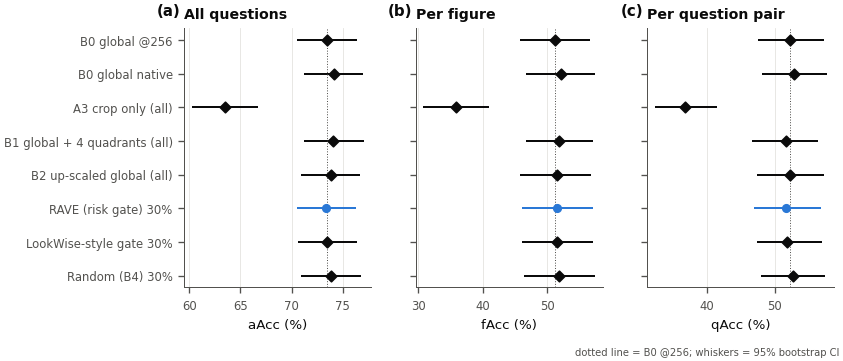

⏱ P4.A7a figure: HallusionBench metrics | wall 1.83 s | CPU 1.68 s (0.92 cores, sys 8.4%) | GPU 0.00 s (no GPU used) | RAM peak 9 GB | A100 time 1.04/7 h
figure -> /content/rave_work/figures/fig8_hallusionbench_by_subcategory.pdf


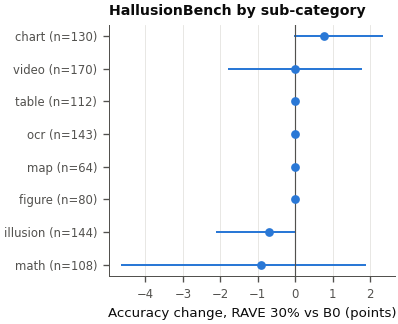

⏱ P4.A7b figure: HallusionBench by sub-category | wall 0.76 s | CPU 0.77 s (1.01 cores, sys 4.5%) | GPU 0.00 s (no GPU used) | RAM peak 9 GB | A100 time 1.04/7 h
⏱ cell 14: import textwrap | wall 2.62 s | CPU 2.48 s (0.95 cores, sys 7.3%) | GPU busy 0.00 s [nvml_util], util 0.0%, 0.15 kJ, peak 17.54 GB | RAM peak 9 GB | A100 time 1.04/7 h


In [16]:
import textwrap
if HB_RESULTS:
    with Phase("P4.A7a figure: HallusionBench metrics", budget_min=2):
        T_ = HB_RESULTS["table"]
        fig, axs = plt.subplots(1, 3, figsize=(COL2, 0.26 * len(T_) + 1.0), sharey=True)
        ys = np.arange(len(T_))[::-1]
        for ax, (k, lt) in zip(axs, (("aAcc", "a"), ("fAcc", "b"), ("qAcc", "c"))):
            for yv, (_, r) in zip(ys, T_.iterrows()):
                is_rave = r.Method.startswith(NAMES["RAVE_risk"])
                col = COLORS["RAVE_risk"] if is_rave else INK
                ax.plot([r[f"{k}_lo"], r[f"{k}_hi"]], [yv, yv], color=col, lw=1.2)
                ax.scatter([r[k]], [yv], s=20, color=col, zorder=3, marker="o" if is_rave else "D")
            base_v = T_.iloc[0][k]
            ax.axvline(base_v, color=INK2, lw=0.6, ls=":")
            ax.set_xlabel(f"{k} (%)")
            ax.set_title({"aAcc": "All questions", "fAcc": "Per figure", "qAcc": "Per question pair"}[k])
            ax.grid(axis="y", visible=False)
            panel(ax, lt)
        axs[0].set_yticks(ys, [textwrap.shorten(m, 34, placeholder="…") for m in T_.Method])
        fig.text(0.99, 0.005, f"dotted line = B0 @{MAIN_BASE}; whiskers = 95% bootstrap CI", ha="right", fontsize=6,
                 color=INK2)
        fig.tight_layout(w_pad=1.2, rect=(0, 0.03, 1, 1))
        save_fig(fig, "fig7_hallusionbench")

    with Phase("P4.A7b figure: HallusionBench by sub-category", budget_min=2):
        EVH, sets = HB_RESULTS["ev"], HB_RESULTS["sets"]
        dlt = EVH.policy(MAIN_BASE, sets["RAVE_risk"])["correct"] - EVH.RES[MAIN_BASE]["global"]["correct"]
        HQd = EVH.Q
        rows_ = []
        for sc in sorted(HQd.subcategory.unique()):
            sel = (HQd.subcategory == sc).values
            if sel.sum() >= 3:
                m_, lo_, hi_ = boot_ci_fast(dlt[sel])
                rows_.append((sc, int(sel.sum()), 100 * m_, 100 * lo_, 100 * hi_))
        rows_ = sorted(rows_, key=lambda r: r[2])
        fig, ax = plt.subplots(figsize=(COL1, 0.26 * max(len(rows_), 3) + 0.8))
        ys = np.arange(len(rows_))
        for yv, (lab, n_, m_, lo_, hi_) in zip(ys, rows_):
            ax.plot([lo_, hi_], [yv, yv], color=COLORS["RAVE_risk"], lw=1.2)
            ax.scatter([m_], [yv], s=18, color=COLORS["RAVE_risk"], zorder=3)
        ax.axvline(0, color=INK2, lw=0.7)
        ax.set_yticks(ys, [f"{lab} (n={n_})" for lab, n_, *_ in rows_])
        ax.set_xlabel("Accuracy change, RAVE 30% vs B0 (points)")
        ax.set_title("HallusionBench by sub-category"); ax.grid(axis="y", visible=False)
        fig.tight_layout()
        save_fig(fig, "fig8_hallusionbench_by_subcategory")
else:
    print("Part A not run")

## Part B — Replication on a second backbone (Qwen3-VL-4B, MMMU-Pro standard-10)
Same Portion 1 crops and prompts, same gate specifications re-fitted out-of-fold on the 4B model's own Stage-1
answers, same merge M2. Results are compared with Portion 3's 8B hypotheses side by side.

In [17]:
R4 = {}
if RUN_4B:
    free_model()
    use_dataset(MM, R4_PRED, "4b|")
    setup_model(MODEL_4B)
    with Phase("P4.B1 verify token counts (4B)", budget_min=3):
        check_tokens([f"global@{MAIN_BASE}", f"joint_top1@{MAIN_BASE}"], n=8)
    ensure_profile()
    R4_DONE, R4_SKIPPED = dense_passes(R4_B0 + R4_ESC, "4B")

model freed: 0.0 GB still allocated on the GPU


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

⏱ P4 load Qwen3-VL-4B-Instruct (BF16) | wall 30.47 s | CPU 5.73 s (0.19 cores, sys 4.4%) | GPU busy 1.42 s [nvml_util], util 4.7%, 1.76 kJ, peak 8.89 GB | RAM peak 9 GB | A100 time 1.05/7 h
Qwen/Qwen3-VL-4B-Instruct on NVIDIA A100-SXM4-40GB | attention=sdpa | memory 42 GB | image_token_id=151655 | transformers 5.18.0
GPU: weights 8.9 GB of 42 GB
host RAM 90 GB (60 GB free) -> loader budget 24 GB: 8 workers x 2 batches, <= 29,592 visual tokens per batch
  global@256               visual/sequence tokens vs pre-stage: exact match
  joint_top1@256           visual/sequence tokens vs pre-stage: exact match
⏱ P4.B1 verify token counts (4B) | wall 0.23 s | CPU 0.38 s (1.64 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 9 GB | A100 time 1.05/7 h
re-using the 8B profile (NVIDIA A100-SXM4-40GB): MAX_TOK=8192, <= 29,592 visual tokens/batch, 7,300 tok/s wall (smaller models are faster)
projected minutes: {'global@256': 1.4, 'global@1024': 2.1, 'global@128': 1.1, 'global@512': 1.7, 'global

global@256:   0%|          | 0/77 [00:00<?, ?it/s]

⏱ P4 4B dense pass global@256 | wall 47.55 s | CPU 76.48 s (1.61 cores, sys 14.3%) | GPU busy 45.03 s [cuda_events], util 89.0%, 16.66 kJ, peak 9.95 GB | RAM peak 12 GB | A100 time 1.06/7 h
⏱ A100 time after 4B global@256: 1.06 h used, 5.94 h left of 7 h (P2–P4 cells)


...

⏱ P4 4B dense pass b2_upscaled@256 | wall 88.58 s | CPU 149.03 s (1.68 cores, sys 12.5%) | GPU busy 85.85 s [cuda_events], util 93.3%, 32.79 kJ, peak 10.16 GB | RAM peak 13 GB | A100 time 1.19/7 h
⏱ A100 time after 4B b2_upscaled@256: 1.19 h used, 5.81 h left of 7 h (P2–P4 cells)


croponly_top1@256:   0%|          | 0/103 [00:00<?, ?it/s]

⏱ P4 4B dense pass croponly_top1@256 | wall 64.46 s | CPU 107.79 s (1.67 cores, sys 15.1%) | GPU busy 61.94 s [cuda_events], util 92.0%, 23.46 kJ, peak 10.15 GB | RAM peak 13 GB | A100 time 1.21/7 h
⏱ A100 time after 4B croponly_top1@256: 1.21 h used, 5.79 h left of 7 h (P2–P4 cells)


joint_rand@256:   0%|          | 0/144 [00:00<?, ?it/s]

⏱ P4 4B dense pass joint_rand@256 | wall 93.02 s | CPU 156.12 s (1.68 cores, sys 10.7%) | GPU busy 90.14 s [cuda_events], util 92.6%, 33.93 kJ, peak 10.12 GB | RAM peak 13 GB | A100 time 1.24/7 h
⏱ A100 time after 4B joint_rand@256: 1.24 h used, 5.76 h left of 7 h (P2–P4 cells)
⏱ cell 15: R4 = {} | wall 703.52 s | CPU 1120.21 s (1.59 cores, sys 13.4%) | GPU busy 614.75 s [nvml_util], util 88.1%, 247.03 kJ, peak 10.12 GB | RAM peak 14 GB | A100 time 1.24/7 h


In [18]:
if RUN_4B and f"joint_top1@{MAIN_BASE}" in R4_DONE and f"global@{MAIN_BASE}" in R4_DONE:
    with Phase("P4.B2 replication evaluation (CPU)", budget_min=5):
        B = MAIN_BASE
        Qm = MM["Q"].reset_index(drop=True)
        b0_4 = {b: R4_DONE[f"global@{b}"] for b in BASES if f"global@{b}" in R4_DONE}
        esc_4 = {(v.split("@")[0], B): R4_DONE[v] for v in R4_ESC if v in R4_DONE}
        EV4 = Evaluator(Qm, {B: b0_4[B]}, esc_4, costs=json.loads(COST_FILE.read_text()) if COST_FILE.exists() else {},
                        cost_tag="4b|")
        d4, S4, AUC4 = fit_gates(b0_4[B], Qm, B)
        S4["RAVE_VoI"] = crossfit(LR, features(d4, B, "full").values, EV4.MERGE[B]["joint_top1"]["M2"],
                                  EV4.folds)[0] - (1 - S4["RAVE_risk"])
        E4 = esc_mask(S4["RAVE_risk"], MAIN_RATE)
        g4 = EV4.RES[B]["global"]["correct"]
        c4 = EV4.policy(B, E4)["correct"]
        T4 = {}
        def add4(hid, desc, a, b_, binary=True):
            d_, lo_, hi_, p_ = paired_boot(a, b_, n=N_BOOT)
            T4[hid] = dict(hypothesis=desc, diff_pts=100 * d_, ci_lo=100 * lo_, ci_hi=100 * hi_, p_boot=p_,
                           mcnemar_p=mcnemar_exact(a, b_)[2] if binary else None)
        add4("H0", "RAVE (30%) vs B0 at the same budget", c4, g4)
        add4("H1", "RAVE vs LookWise-style gate", c4, EV4.policy(B, esc_mask(S4["LookWise_conf"], MAIN_RATE))["correct"])
        add4("H2", "RAVE vs random (expected)", c4, EV4.b4_expected(B, MAIN_RATE), binary=False)
        if EV4.has(B, "b2_upscaled"):
            add4("H3", "escalated: crop vs B2 up-scaled global", EV4.MERGE[B]["joint_top1"]["M2"][E4],
                 EV4.MERGE[B]["b2_upscaled"]["M2"][E4])
        if EV4.has(B, "croponly_top1"):
            add4("H4", "escalated: global+crop vs crop only", EV4.MERGE[B]["joint_top1"]["M2"][E4],
                 EV4.MERGE[B]["croponly_top1"]["M2"][E4])
        add4("H5", "RAVE vs LazyMCoT-style router", c4, EV4.policy(B, esc_mask(S4["LazyMCoT_GBDT"], MAIN_RATE))["correct"])
        add4("H6", "VoI vs RAVE risk", EV4.policy(B, esc_mask(S4["RAVE_VoI"], MAIN_RATE))["correct"], c4)
        if EV4.has(B, "joint_rand"):
            add4("H9a", "escalated: OpenCLIP crop vs random crop", EV4.MERGE[B]["joint_top1"]["M2"][E4],
                 EV4.MERGE[B]["joint_rand"]["M2"][E4])
        if len(b0_4) >= 2:
            pol4 = EV4.policy(B, E4)
            d7, lo7, hi7, p7 = frontier_gap(c4, pol4["tok"], list(b0_4.values()), Qm.qid, n_boot=2000)
            T4["H7"] = dict(hypothesis="RAVE above the B0 frontier at equal tokens", diff_pts=100 * d7,
                            ci_lo=100 * lo7, ci_hi=100 * hi7, p_boot=p7)
        prim = {h: T4[h]["p_boot"] for h in ("H1", "H2", "H3", "H4") if h in T4}
        for h, v in holm(prim).items():
            T4[h].update(p_holm=v["p_holm"], reject_holm=v["reject"])
        CURVES4 = EV4.curves(B, {k: S4[k] for k in ("RAVE_risk", "RAVE_VoI", "LookWise_conf", "LazyMCoT_GBDT")})
        CURVES4.to_csv(R4_PRED / "policy_curves_4b.csv", index=False)
        FRONT4 = pd.DataFrame([dict(base=b, acc=df.correct.mean(), tok=df.vis_tokens.mean()) for b, df in b0_4.items()]
                              ).sort_values("tok").reset_index(drop=True)
        rep_rows = []
        for h in ("H0", "H1", "H2", "H3", "H4", "H5", "H6", "H7", "H9a"):
            r8, r4 = TESTS_8B.get(h), T4.get(h)
            if r4 is None:
                continue
            fmt = lambda r: "–" if not r else f"{r['diff_pts']:+.1f} [{r['ci_lo']:+.1f}, {r['ci_hi']:+.1f}]"
            rep_rows.append({"Hypothesis": f"{h}: {T4[h]['hypothesis']}",
                             f"Main ({MODEL_8B.split('/')[-1]}) Δ pts [95% CI]": fmt(r8),
                             f"Replication ({MODEL_4B.split('/')[-1]}) Δ pts [95% CI]": fmt(r4)})
        REP_T = pd.DataFrame(rep_rows)
        REP_T.to_csv(R4_PRED / "table_replication.csv", index=False)
        to_booktabs(REP_T, R4_PRED / "table_replication.tex",
                    f"Replication of the pre-registered effects on a second backbone (MMMU-Pro standard-10, budget {B}, "
                    f"{int(MAIN_RATE * 100)}% escalated, merge M2).", "tab:replication", align="lrr")
        pd.DataFrame([dict(id=k, **v) for k, v in T4.items()]).to_csv(R4_PRED / "hypothesis_tests_4b.csv", index=False)
        R4 = dict(ev=EV4, tests=T4, auc=AUC4, curves=CURVES4, front=FRONT4, table=REP_T)
    print(f"4B B0 accuracy at {B}: {g4.mean():.2%} | RAVE 30%: {c4.mean():.2%} | gate AUROC:",
          {k: round(v, 3) for k, v in AUC4.items()})
    print(REP_T.to_string(index=False))
elif RUN_4B:
    print("4B passes were skipped (A100 time) — nothing to evaluate")

LaTeX table -> /content/rave_work/preds/qwen3vl4b/table_replication.tex
⏱ P4.B2 replication evaluation (CPU) | wall 4.64 s | CPU 18.67 s (4.02 cores, sys 37.6%) | GPU 0.00 s (no GPU used) | RAM peak 9 GB | A100 time 1.24/7 h
4B B0 accuracy at 256: 36.30% | RAVE 30%: 36.65% | gate AUROC: {'A1_entropy': np.float64(0.697), 'LookWise_conf': np.float64(0.699), 'LazyMCoT_GBDT': np.float64(0.685), 'RAVE_risk': np.float64(0.703)}
                                    Hypothesis Main (Qwen3-VL-8B-Instruct) Δ pts [95% CI] Replication (Qwen3-VL-4B-Instruct) Δ pts [95% CI]
       H0: RAVE (30%) vs B0 at the same budget                          -0.2 [-0.5, +0.1]                                 +0.3 [-0.3, +1.0]
               H1: RAVE vs LookWise-style gate                          +0.1 [-0.2, +0.3]                                 +0.1 [-0.3, +0.5]
                 H2: RAVE vs random (expected)                          -0.1 [-0.3, +0.1]                                 +0.2 [-0.2, +0.7]
    H3: escala

### B.3 Figure — replication
* **Fig. 9** (a) Qwen3-VL-4B accuracy against average visual tokens: uniform resolution vs. the gated policies;
  (b) every pre-registered effect for 8B and 4B side by side (accuracy points, 95% CIs).

figure -> /content/rave_work/figures/fig9_replication_4b.pdf


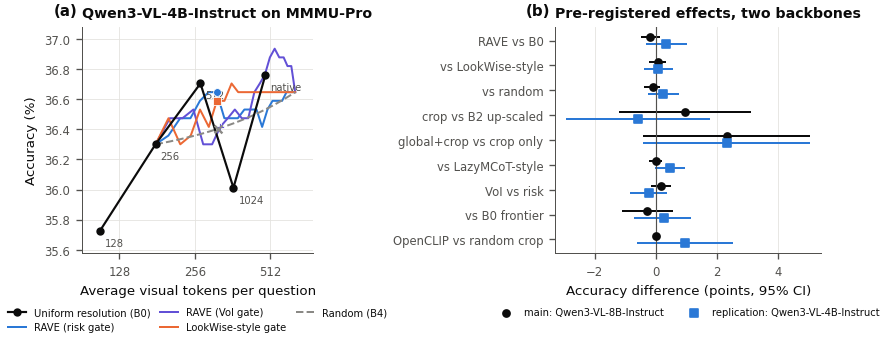

⏱ P4.B3 figure: replication | wall 1.39 s | CPU 1.40 s (1.01 cores, sys 8.4%) | GPU 0.00 s (no GPU used) | RAM peak 9 GB | A100 time 1.24/7 h
⏱ cell 17: if R4: | wall 1.40 s | CPU 1.42 s (1.01 cores, sys 9.0%) | GPU busy 0.00 s [nvml_util], util 0.0%, 0.08 kJ, peak 8.89 GB | RAM peak 9 GB | A100 time 1.24/7 h


In [19]:
if R4:
    with Phase("P4.B3 figure: replication", budget_min=2):
        fig, axs = plt.subplots(1, 2, figsize=(COL2, 3.15), gridspec_kw=dict(width_ratios=[1, 1.15]))
        ax = axs[0]
        F4, C4 = R4["front"], R4["curves"]
        ax.plot(F4.tok, 100 * F4.acc, color=COLORS["B0"], marker="o", ms=4, lw=1.3, label=NAMES["B0"], zorder=4)
        for r_ in F4.itertuples():
            ax.annotate(str(r_.base), (r_.tok, 100 * r_.acc), xytext=(3, -9), textcoords="offset points", fontsize=6,
                        color=INK2)
        for name in ("RAVE_risk", "RAVE_VoI", "LookWise_conf", "B4_random"):
            cv = C4[C4.policy == name].sort_values("rate")
            ax.plot(cv.tok, 100 * cv.acc, color=COLORS[name], lw=1.2, ls="--" if name == "B4_random" else "-",
                    label=NAMES[name])
            op = cv[cv.rate == MAIN_RATE]
            edge = {} if MARKERS[name] in ("x", "+") else dict(edgecolor="white", linewidth=0.5)
            ax.scatter(op.tok, 100 * op.acc, color=COLORS[name], marker=MARKERS[name], s=22, zorder=5, **edge)
        allx = np.r_[F4.tok.values, C4.tok.values]
        token_axis(ax, allx.min(), allx.max())
        ax.set_xlabel("Average visual tokens per question"); ax.set_ylabel("Accuracy (%)")
        ax.set_title(f"{MODEL_4B.split('/')[-1]} on MMMU-Pro")
        ax.margins(y=0.12)
        ax.legend(fontsize=6, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False,
                  handlelength=1.8, columnspacing=1.0)
        panel(ax, "a")
        ax = axs[1]
        labels = {"H0": "RAVE vs B0", "H1": "vs LookWise-style", "H2": "vs random", "H3": "crop vs B2 up-scaled",
                  "H4": "global+crop vs crop only", "H5": "vs LazyMCoT-style", "H6": "VoI vs risk",
                  "H7": "vs B0 frontier", "H9a": "OpenCLIP vs random crop"}
        hs = [h for h in labels if h in R4["tests"]]
        ys = np.arange(len(hs))[::-1]
        for yv, h in zip(ys, hs):
            for off, src, col, mk, lab in ((0.14, TESTS_8B.get(h), INK, "o", "main: " + MODEL_8B.split("/")[-1]),
                                           (-0.14, R4["tests"].get(h), COLORS["RAVE_risk"], "s",
                                            "replication: " + MODEL_4B.split("/")[-1])):
                if not src:
                    continue
                ax.plot([src["ci_lo"], src["ci_hi"]], [yv + off] * 2, color=col, lw=1.2)
                ax.scatter([src["diff_pts"]], [yv + off], color=col, marker=mk, s=18, zorder=3,
                           label=lab if h == hs[0] else None)
        ax.axvline(0, color=INK2, lw=0.7)
        ax.set_yticks(ys, [labels[h] for h in hs])
        ax.set_xlabel("Accuracy difference (points, 95% CI)")
        ax.set_title("Pre-registered effects, two backbones"); ax.grid(axis="y", visible=False)
        ax.legend(fontsize=6, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)
        panel(ax, "b")
        fig.tight_layout(w_pad=2)
        save_fig(fig, "fig9_replication_4b")
else:
    print("Part B not run")

## Summary — results, CPU/GPU time of Portion 4 and of the whole A100 budget; save to Drive

In [20]:
summary = dict(hallusionbench=dict(n=int(HB_RESULTS["ev"].N) if HB_RESULTS else 0,
                                   table=HB_RESULTS["table"].round(2).to_dict("records") if HB_RESULTS else [],
                                   tests=HB_RESULTS.get("tests", {}) if HB_RESULTS else {},
                                   skipped=HB_SKIPPED if RUN_HB and "HB_SKIPPED" in globals() else []),
               replication_4b=dict(tests=R4.get("tests", {}) if R4 else {},
                                   skipped=R4_SKIPPED if RUN_4B and "R4_SKIPPED" in globals() else []),
               figures=sorted(p.name for p in FIG_DIR.glob("*.pdf")))
(DIRS["logs"] / "results_summary_p4.json").write_text(json.dumps(summary, indent=2, default=float))
window("end of Portion 4")
time_report("P4")
print()
time_report()            # every portion: total CPU, GPU and wall time
sync_to_drive(quiet=False)
save_notebook_copy("RAVE_v4_P4_generalisation")

⏱ A100 time end of Portion 4: 1.24 h used, 5.76 h left of 7 h (P2–P4 cells)
[P4] 17 cells | wall 28.7 min | CPU 58.8 CPU-min (2.1 cores avg) | GPU busy 20.00 min (phases) / 18.83 min (cells, NVML) | GPU energy 477.1 kJ | A100 time used (P2–P4) 1.24 h of 7

[all notebooks] 71 cells | wall 87.3 min | CPU 172.9 CPU-min (2.0 cores avg) | GPU busy 71.36 min (phases) / 63.54 min (cells, NVML) | GPU energy 1570.7 kJ | A100 time used (P2–P4) 1.24 h of 7
Drive sync: 1 file(s) -> /content/drive/MyDrive/Koushik 2/rave_work
notebook with outputs -> /content/drive/MyDrive/Koushik 2/notebooks/RAVE_v4_P4_generalisation_executed_20261019_0905.ipynb
⏱ cell 18: summary = dict(hallusionbench=dict(n=int(HB_RESULTS["ev"].N) | wall 3.37 s | CPU 0.11 s (0.03 cores, sys 1.4%) | GPU busy 0.00 s [nvml_util], util 0.0%, 0.19 kJ, peak 8.89 GB | RAM peak 9 GB | A100 time 1.24/7 h
